<a href="https://colab.research.google.com/github/hanjeongseop/Data/blob/main/1_DDA(%EB%AC%98%EC%82%AC%EC%A0%81_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. 각 공정 별 주요 인자 탐색

In [1]:
# 필요한 라이브러리 정의

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
# 파일 읽기 및 내용 확인하기

github_csv_url = 'https://raw.githubusercontent.com/hanjeongseop/Data/main'

df1_oxid = pd.read_csv(github_csv_url + '/Oxid.csv')

df1_oxid

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime
0,1,Oxidation,dry,1138.979159,O2,32.80,0.200,62,699.443,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,1,Oxidation,dry,1218.184551,O2,31.86,0.194,137,696.792,NOLSM212,1,2,17-02-2019 PM 9:04:30
2,1,Oxidation,dry,1062.467808,O2,39.51,0.217,128,705.471,NOLSM313,1,3,17-02-2019 PM 9:04:30
3,1,Oxidation,dry,1114.704773,O2,32.88,0.201,90,710.772,NOLSM414,1,4,17-02-2019 PM 9:04:30
4,1,Oxidation,dry,989.411946,O2,38.11,0.204,98,716.975,NOLSM515,1,5,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,3,Oxidation,wet,1275.182502,H2O,45.10,0.214,21,715.498,NOLSM8483211,32,11,17-02-2019 PM 9:04:30
848,1,Oxidation,wet,1268.105427,H2O,45.07,0.215,22,707.179,NOLSM8493212,32,12,17-02-2019 PM 9:04:30
849,1,Oxidation,wet,1279.160563,H2O,45.12,0.214,21,712.946,NOLSM8503213,32,13,17-02-2019 PM 9:04:30
850,1,Oxidation,wet,1272.804948,H2O,45.34,0.213,20,711.987,NOLSM8513214,32,14,17-02-2019 PM 9:04:30


##################################################################
데이터를 읽어온 후 확인해야 하는 일
##################################################################
1) 데이터 구조 : 데이터의 개수 / 항목
2) 데이터 타입 : 각 항목의 데이터 타입 ( 연속형 / 범주형 )
3) 기술통계량
* 연속형 : 대표값 / 산포 / 분포의 모양 / 결측치
- 대표값 : 평균 / 중앙값
  ex) A집단 : 1,2,3,4,5 의 평균값은 3 / 중앙값은 3
      B집단 : 1,2,3,4,1000 의 평균값은 약 200 / 중앙값 3

- 산포 : 표준편차 / 최소값 / 최대값 ====> 데이터의 신뢰성을 판단할 수 있는 값
- 분포의 모양 : 정규 분표
- 결측치 (Missing Value)

* 범주형 : 각 항목의 빈도수 / 결측치 (Missing Value)

In [3]:
df1_oxid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852 entries, 0 to 851
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Ox_Chamber  852 non-null    int64  
 1   process     852 non-null    object 
 2   type        852 non-null    object 
 3   Temp_OXid   852 non-null    float64
 4   Vapor       852 non-null    object 
 5   ppm         852 non-null    float64
 6   Pressure    852 non-null    float64
 7   Oxid_time   852 non-null    int64  
 8   thickness   852 non-null    float64
 9   No_Die      852 non-null    object 
 10  Lot_Num     852 non-null    int64  
 11  Wafer_Num   852 non-null    int64  
 12  Datetime    852 non-null    object 
dtypes: float64(4), int64(4), object(5)
memory usage: 86.7+ KB


# 전체 데이터 수는 852건

######### 데이터 형식
# int64 : 정수형
# float64 : 실수형
# object : 문자형

In [4]:
df1_oxid.describe()

,Ox_Chamber,Temp_OXid,ppm,Pressure,Oxid_time,thickness,Lot_Num,Wafer_Num
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000
mean,2.00000,1064.415784,33.202242,0.211374,123.201878,710.926810,16.281690,13.894366
std,0.81265,149.550147,8.494070,0.009067,76.285130,8.082856,9.116841,7.785951
min,1.00000,862.011276,21.070000,0.180000,-6.000000,681.435000,1.000000,1.000000
25%,1.00000,874.756813,22.450000,0.205000,52.000000,706.313000,8.000000,7.000000
50%,2.00000,1069.240209,33.420000,0.213000,116.000000,711.590500,16.000000,14.000000
75%,3.00000,1189.172249,40.452500,0.217000,217.000000,715.595000,24.000000,21.000000
max,3.00000,1339.476675,49.910000,0.229000,291.000000,737.402000,32.000000,27.000000


### [해석]

### 1. mean값과 50%값과 차이가 많이 나지 않는다
### 2. min값과 max값을 확인해 보니 Oxid_time에서 min값이 -6으로 이상치로 의심된다.

### 위의 내용을 정확하게 판단하기 위해서는 현장 담당자와의 미팅을 통해 확인가능하다.
### 따라서 데이터 분석을 위해서는 도메인 지식이 풍부한 현장 담당자의 참여가 필수다.

<Axes: xlabel='Temp_OXid', ylabel='Count'>

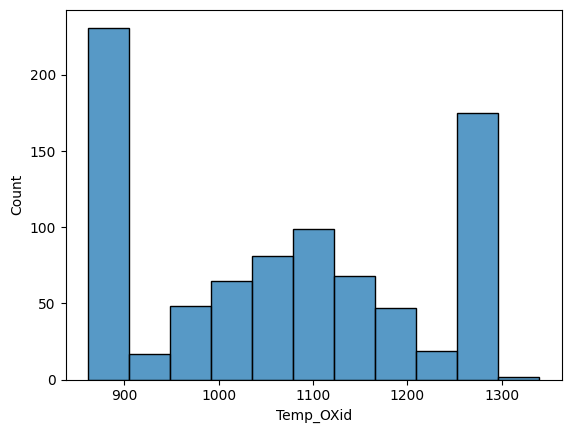

In [5]:
# 데이터의 분포를 확인하기 위해 히스토그램을 이용한다

sns.histplot(data=df1_oxid, x='Temp_OXid')

### [해석]

### 히스토그램을 확인해본 결과 정규분포를 띄지 않는 것을 확인할 수 있다.

### 이런 경우 상세하게 살펴보기 위해 "층별화"를 이용한다.

<Axes: xlabel='Temp_OXid', ylabel='Count'>

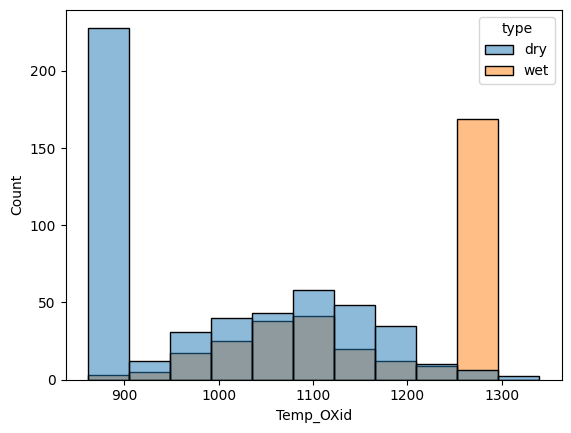

In [6]:
# 옥시데이션의 공정에는 dry와 wet 방식이 있다는 것을 알고있다.

# 공정에 따른 데이터의 분포를 확인하기 위해 층별화를 그린다

sns.histplot(data=df1_oxid, x='Temp_OXid', hue='type')

### [해석]

### 데이터를 확인해보니 정규분포를 띄지는 않지만
### dry 공정에서는 900도가 적정한 온도이며
### wet 공정에서는 1200 ~ 1300도 사이가 적정한 온도로 확인된다.

### 따라서 중앙에 있는 데이터가 이상치일 확률이 높다.

<Axes: xlabel='Oxid_time', ylabel='Count'>

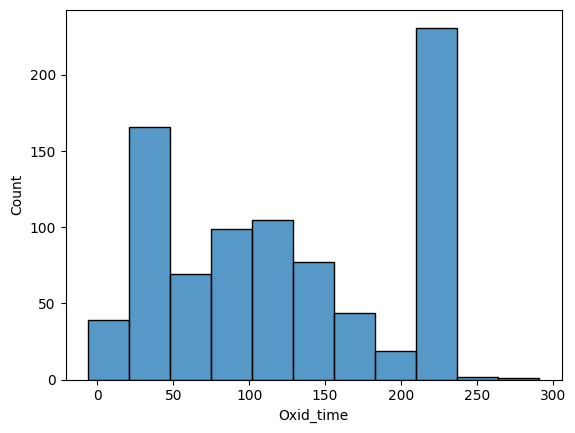

In [7]:
# 데이터의 분포를 확인하기 위해 히스토그램을 이용한다

sns.histplot(data=df1_oxid, x='Oxid_time')

<Axes: xlabel='Oxid_time', ylabel='Count'>

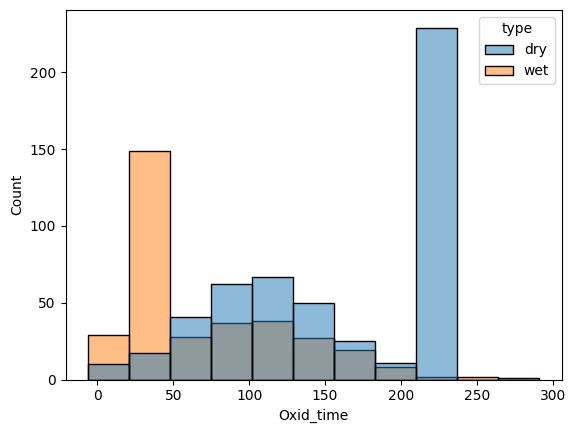

In [8]:
# 공정에 따른 데이터의 분포를 확인하기 위해 층별화를 그린다

sns.histplot(data=df1_oxid, x='Oxid_time', hue='type')

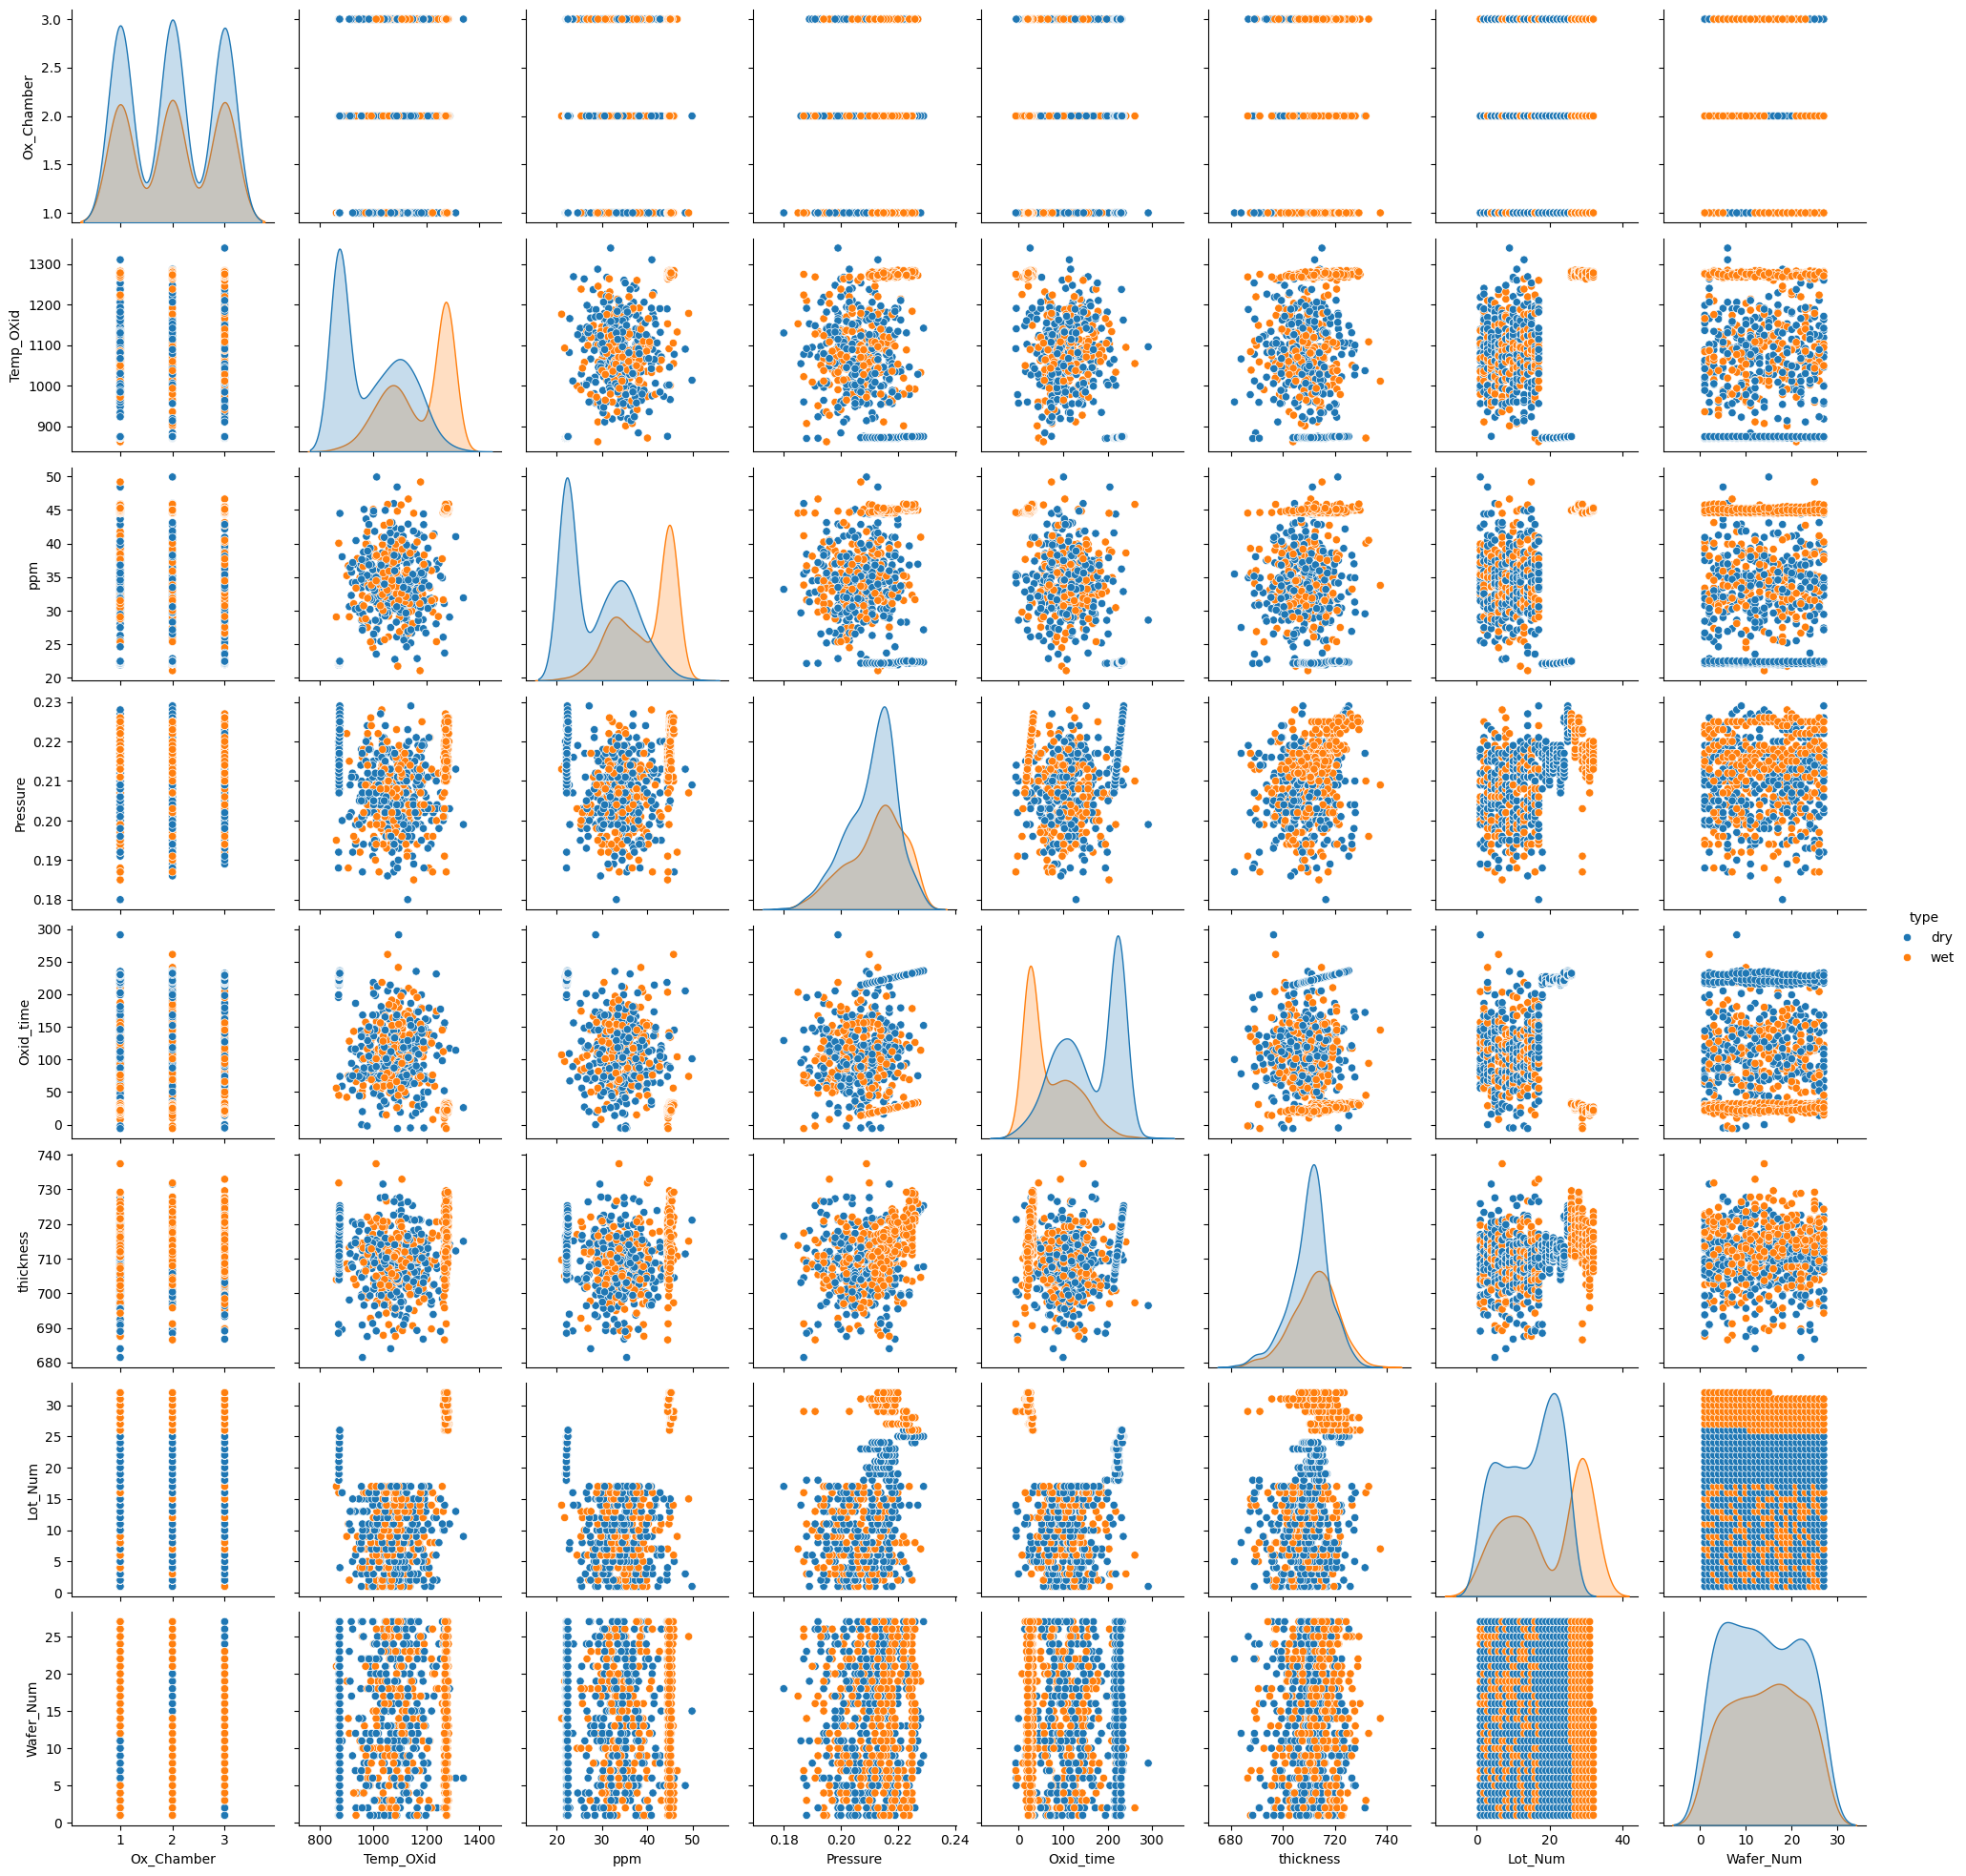

In [9]:
# 모든 숫자데이터의 층별화 / 히스토그램 / 산점도를 확인해보자

sns.pairplot(data=df1_oxid, hue='type')

In [10]:
# 빈도수를 확인해보자 ( 실제 반도체 공정에서는 wet 공정을 잘 사용하지 않지만, 교육을 위해 구분함)

df1_oxid['type'].value_counts()

,count
type,
dry,513
wet,339


In [11]:
df1_oxid['Vapor'].value_counts()

,count
Vapor,
O2,513
H2O,339


In [12]:
df1_oxid['Ox_Chamber'].value_counts()

,count
Ox_Chamber,
2,290
1,281
3,281


<Axes: xlabel='Ox_Chamber', ylabel='count'>

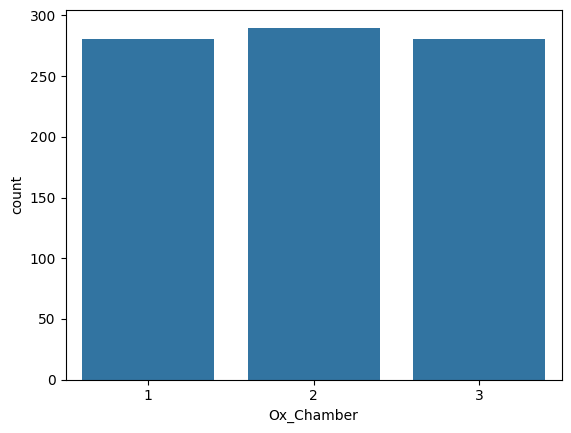

In [13]:
# 범주형 데이터 시각화를 진행해보자

sns.countplot(data=df1_oxid, x='Ox_Chamber')

In [14]:
# 결측치를 확인하자

df1_oxid.isnull().sum()

,0
Ox_Chamber,0
process,0
type,0
Temp_OXid,0
Vapor,0
ppm,0
Pressure,0
Oxid_time,0
thickness,0
No_Die,0


# 나머지 데이터 로드 후 위의 과정 반복

In [15]:
# Etching.csv
# Photo_Softbake
# Photo_lithography
# Implant
# Inspect

df1_etch = pd.read_csv(github_csv_url + '/Etching.csv')

df1_etch

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09


In [16]:
df1_etch.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852 entries, 0 to 851
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       852 non-null    int64  
 1   Etching_Chamber  852 non-null    int64  
 2   Process 3        852 non-null    object 
 3   Temp_Etching     852 non-null    float64
 4   Source_Power     852 non-null    float64
 5   Selectivity      852 non-null    float64
 6   No_Die           852 non-null    object 
 7   Lot_Num          852 non-null    int64  
 8   Wafer_Num        852 non-null    int64  
 9   Datetime         852 non-null    object 
 10  Thin Film 4      851 non-null    float64
 11  Thin Film 3      851 non-null    float64
 12  Thin Film 2      851 non-null    float64
 13  Thin Film 1      851 non-null    float64
dtypes: float64(7), int64(4), object(3)
memory usage: 93.3+ KB


In [17]:
df1_etch.describe()

,Unnamed: 0,Etching_Chamber,Temp_Etching,Source_Power,Selectivity,Lot_Num,Wafer_Num,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,851.000000,851.000000,851.000000,851.000000
mean,425.50000,1.967136,71.147822,51.227459,1.032140,16.281690,13.894366,296.633373,311.276439,347.799401,404.940012
std,246.09551,0.830584,0.824158,0.634215,0.016238,9.116841,7.785951,125.378446,125.714630,125.774630,125.790535
min,0.00000,1.000000,68.150000,49.342000,0.984000,1.000000,1.000000,-49.000000,-34.650000,2.000000,59.380000
25%,212.75000,1.000000,70.709750,50.794500,1.022000,8.000000,7.000000,202.000000,216.525000,252.880000,310.185000
50%,425.50000,2.000000,71.220500,51.247000,1.033500,16.000000,14.000000,281.000000,295.970000,332.480000,389.630000
75%,638.25000,3.000000,71.656500,51.698250,1.043000,24.000000,21.000000,372.000000,386.675000,423.050000,480.355000
max,851.00000,3.000000,73.081000,53.272000,1.076000,32.000000,27.000000,687.000000,700.240000,736.510000,793.500000


### [해석]

### 1. mean값과 50%값과 차이가 많이 나지 않는다
###    다만, Thin Film1 ~ 4 까지의 컬럼에서는 차이가 발생하고 있다.
### 2. min값과 max값을 확인해 보니 Thin Film 4에서 min값이 -149, Thin Film 3	에서 min값이 -34로 이상치로 의심된다.
### 위의 내용을 정확하게 판단하기 위해서는 현장 담당자와의 미팅을 통해 확인가능하다.
### 따라서 데이터 분석을 위해서는 도메인 지식이 풍부한 현장 담당자의 참여가 필수다.

<Axes: xlabel='Thin Film 3', ylabel='Count'>

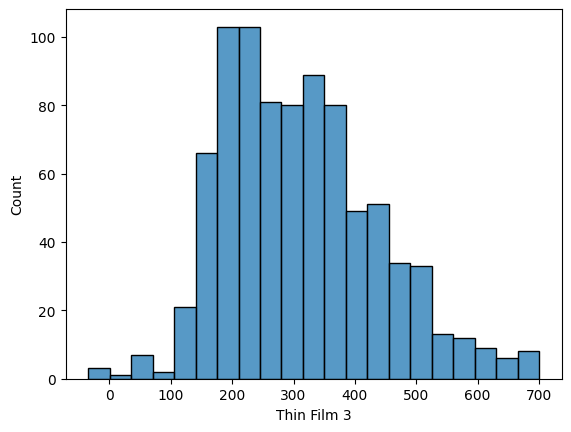

In [18]:
# 데이터의 분포를 확인하기 위해 히스토그램을 이용한다

sns.histplot(data=df1_etch, x='Thin Film 3')

<Axes: xlabel='Thin Film 4', ylabel='Count'>

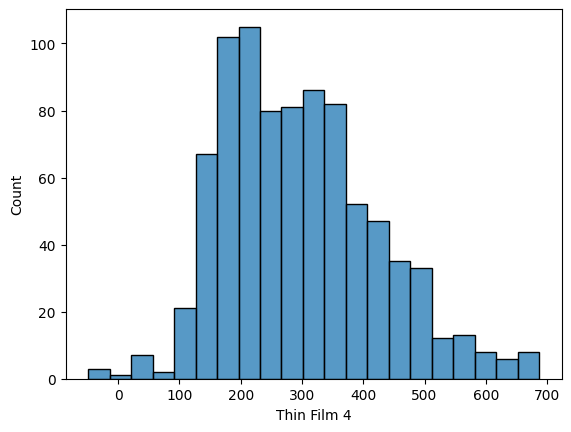

In [19]:
sns.histplot(data=df1_etch, x='Thin Film 4')

### [해석]

### 히스토그램을 확인해본 결과 좌측으로 치우쳐 있지만 정규분포를 띄고 있는것 같다.

### '층별화'를 통해 다시 살펴보자.

<Axes: xlabel='Thin Film 3', ylabel='Count'>

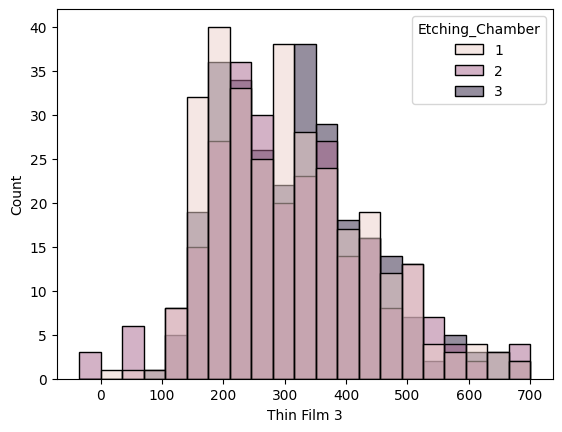

In [20]:
# 에칭공정에는 총 3개의 Chamber가 있다는 것을 알고있다.
#  ====> 기준대상은 범주형 데이터를 기준으로 하지만, 숫자형의 경우에는 데이터를 구분할 수 있는 성격인 경우 활용할 수 있다.

# Chamber에 따른 데이터의 분포를 확인하기 위해 층별화를 그린다

sns.histplot(data=df1_etch, x='Thin Film 3', hue='Etching_Chamber')

<Axes: xlabel='Thin Film 4', ylabel='Count'>

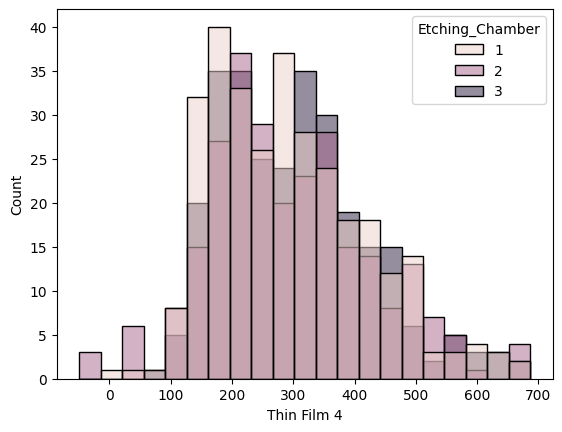

In [21]:
# 에칭공정에는 총 3개의 Chamber가 있다는 것을 알고있다.

# Chamber에 따른 데이터의 분포를 확인하기 위해 층별화를 그린다

sns.histplot(data=df1_etch, x='Thin Film 4', hue='Etching_Chamber')

### [해석]

### 1 공정에서는 약 170 나노미리
### 2 공정에서는 약 220 나노미리
### 3 공정에서는 약 320 나노미리가 적정한 두께로 확인된다.

### 따라서 좌, 우측 데이터가 이상치일 확률이 높다.

In [22]:
# 모든 숫자데이터의 층별화 / 히스토그램 / 산점도를 확인해보자

sns.pairplot(data=df1_etch, hue='Etching_Chamber')

Output hidden; open in https://colab.research.google.com to view.

In [23]:
# 빈도수를 확인해보자

df1_etch['Etching_Chamber'].value_counts()

,count
Etching_Chamber,
1,308
3,280
2,264


In [24]:
df1_etch['Process 3'].value_counts()

,count
Process 3,
Etching,852


<Axes: xlabel='Etching_Chamber', ylabel='count'>

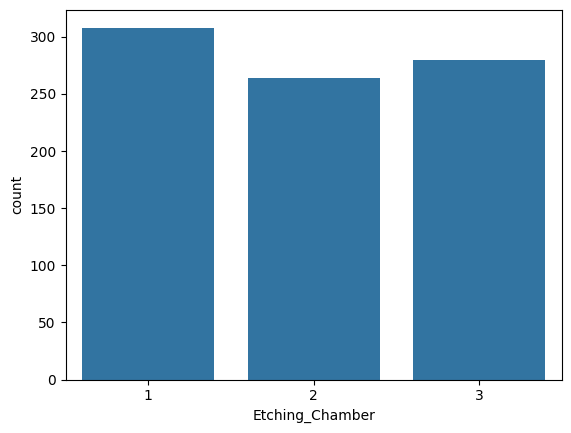

In [25]:
# 범주형 데이터 시각화를 진행해보자

sns.countplot(data=df1_etch, x='Etching_Chamber')

In [26]:
# 결측치를 확인하자

df1_etch.isnull().sum()

,0
Unnamed: 0,0
Etching_Chamber,0
Process 3,0
Temp_Etching,0
Source_Power,0
Selectivity,0
No_Die,0
Lot_Num,0
Wafer_Num,0
Datetime,0


In [27]:
# Etching.csv
# Photo_Softbake
# Photo_lithography
# Implant
# Inspect

df1_softbake = pd.read_csv(github_csv_url + '/Photo_Softbake.csv')

df1_softbake

,Unnamed: 0,photo_soft_Chamber,process 2,resist_target,N2_HMDS,pressure_HMDS,temp_HMDS,temp_HMDS_bake,time_HMDS_bake,spin1,spin2,spin3,photoresist_bake,temp_softbake,time_softbake,No_Die,Lot_Num,Wafer_Num,Datetime
0,0,1,Photo,1.211940,13.891,15.025,20.000,198.792,90.001,504.589,4082.622,5184.620,5.044,90.894,30.009,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,1,1,Photo,0.887720,14.722,15.059,19.995,198.747,89.998,492.196,3960.739,5065.197,5.058,92.334,29.997,NOLSM212,1,2,17-02-2019 PM 9:04:30
2,2,1,Photo,1.113156,19.205,14.964,19.997,202.139,90.000,499.886,3981.691,4873.417,5.151,91.868,30.005,NOLSM313,1,3,17-02-2019 PM 9:04:30
3,3,2,Photo,0.882195,16.368,14.944,19.998,199.649,90.001,505.249,3922.191,5131.972,5.069,91.881,29.997,NOLSM414,1,4,17-02-2019 PM 9:04:30
4,4,2,Photo,0.834001,13.926,14.933,20.002,204.544,90.001,501.089,4124.099,5108.355,5.055,91.212,30.001,NOLSM515,1,5,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Photo,0.859869,16.029,15.005,19.998,204.429,90.000,504.429,4088.587,5110.734,5.114,93.622,29.996,NOLSM8483211,32,11,17-02-2019 PM 9:04:30
848,848,1,Photo,0.914315,17.587,14.949,20.000,204.266,90.000,504.266,4085.330,5106.662,5.083,93.227,29.994,NOLSM8493212,32,12,17-02-2019 PM 9:04:30
849,849,1,Photo,0.915383,16.445,14.978,19.994,203.401,90.000,503.401,4068.014,5085.017,5.098,93.547,29.992,NOLSM8503213,32,13,17-02-2019 PM 9:04:30
850,850,1,Photo,0.719649,15.306,15.050,20.002,203.670,90.000,503.670,4073.408,5091.760,5.107,93.487,30.007,NOLSM8513214,32,14,17-02-2019 PM 9:04:30


In [28]:
df1_softbake.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852 entries, 0 to 851
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          852 non-null    int64  
 1   photo_soft_Chamber  852 non-null    int64  
 2   process 2           852 non-null    object 
 3   resist_target       852 non-null    float64
 4   N2_HMDS             852 non-null    float64
 5   pressure_HMDS       852 non-null    float64
 6   temp_HMDS           852 non-null    float64
 7   temp_HMDS_bake      852 non-null    float64
 8   time_HMDS_bake      852 non-null    float64
 9   spin1               852 non-null    float64
 10  spin2               852 non-null    float64
 11  spin3               852 non-null    float64
 12  photoresist_bake    852 non-null    float64
 13  temp_softbake       852 non-null    float64
 14  time_softbake       852 non-null    float64
 15  No_Die              852 non-null    object 
 16  Lot_Num 

In [29]:
df1_softbake.describe()

,Unnamed: 0,photo_soft_Chamber,resist_target,N2_HMDS,pressure_HMDS,temp_HMDS,temp_HMDS_bake,time_HMDS_bake,spin1,spin2,spin3,photoresist_bake,temp_softbake,time_softbake,Lot_Num,Wafer_Num
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.00000,852.000000,852.000000,852.000000
mean,425.50000,1.989437,0.964429,15.943687,15.003993,19.999478,200.698777,90.000066,500.902367,4025.236340,5019.220893,5.018864,91.97267,30.000674,16.281690,13.894366
std,246.09551,0.819063,0.170563,2.142458,0.078023,0.003637,2.832488,0.000779,2.868512,55.709378,68.686855,0.070206,1.45308,0.006323,9.116841,7.785951
min,0.00000,1.000000,0.500000,9.497000,14.776000,19.986000,191.209000,89.998000,492.196000,3864.820000,4814.620000,4.765000,86.49800,29.982000,1.000000,1.000000
25%,212.75000,1.000000,0.847038,14.664750,14.951750,19.997000,198.785500,90.000000,498.962500,3986.706000,4971.247750,4.969000,91.09550,29.997000,8.000000,7.000000
50%,425.50000,2.000000,0.930296,16.242500,15.003000,20.000000,200.716500,90.000000,500.900500,4026.305500,5020.005000,5.021000,92.04250,30.001000,16.000000,14.000000
75%,638.25000,3.000000,1.076158,17.151750,15.058000,20.002000,202.794250,90.001000,503.174750,4067.947250,5071.710000,5.071000,92.98900,30.005000,24.000000,21.000000
max,851.00000,3.000000,1.500000,23.573000,15.281000,20.012000,209.521000,90.003000,509.055000,4208.676000,5194.134000,5.239000,96.65300,30.023000,32.000000,27.000000


### [해석]

### 1. mean값과 50%값과 차이가 많이 나지 않는다
### 2. min값과 max값을 확인해 봐도 이상치가 없어 보인다.

In [30]:
# 결측치를 확인하자

df1_softbake.isnull().sum()

,0
Unnamed: 0,0
photo_soft_Chamber,0
process 2,0
resist_target,0
N2_HMDS,0
pressure_HMDS,0
temp_HMDS,0
temp_HMDS_bake,0
time_HMDS_bake,0
spin1,0


In [31]:
# Etching.csv
# Photo_Softbake
# Photo_lithography
# Implant
# Inspect

df1_photo = pd.read_csv(github_csv_url + '/Photo_lithography.csv')

df1_photo

,lithography_Chamber,Line_CD,Lamp,UV_type,Wavelength,Resolution,Energy_Exposure,No_Die,Lot_Num,Wafer_Num,Datetime
0,1,30.959,Hg-Arc,H,405,516.657,109.769,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,2,29.653,Hg-Arc,H,405,501.894,107.102,NOLSM212,1,2,17-02-2019 PM 9:04:30
2,3,28.063,Hg-Arc,I,365,506.750,110.471,NOLSM313,1,3,17-02-2019 PM 9:04:30
3,1,31.556,Hg-Arc,I,365,537.603,107.072,NOLSM414,1,4,17-02-2019 PM 9:04:30
4,2,31.969,Hg-Arc,I,365,560.574,108.073,NOLSM515,1,5,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...
847,3,32.525,Hg-Arc,I,365,468.930,106.744,NOLSM8483211,32,11,17-02-2019 PM 9:04:30
848,1,28.001,Hg-Arc,I,365,469.586,106.174,NOLSM8493212,32,12,17-02-2019 PM 9:04:30
849,2,32.110,Hg-Arc,I,365,476.399,106.108,NOLSM8503213,32,13,17-02-2019 PM 9:04:30
850,3,35.822,Hg-Arc,I,365,476.997,106.765,NOLSM8513214,32,14,17-02-2019 PM 9:04:30


In [32]:
df1_photo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852 entries, 0 to 851
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   lithography_Chamber  852 non-null    int64  
 1   Line_CD              851 non-null    float64
 2   Lamp                 852 non-null    object 
 3   UV_type              852 non-null    object 
 4   Wavelength           852 non-null    int64  
 5   Resolution           851 non-null    float64
 6   Energy_Exposure      851 non-null    float64
 7   No_Die               852 non-null    object 
 8   Lot_Num              852 non-null    int64  
 9   Wafer_Num            852 non-null    int64  
 10  Datetime             852 non-null    object 
dtypes: float64(3), int64(4), object(4)
memory usage: 73.3+ KB


In [33]:
df1_photo.describe()

,lithography_Chamber,Line_CD,Wavelength,Resolution,Energy_Exposure,Lot_Num,Wafer_Num
count,852.000000,851.00000,852.000000,851.000000,851.000000,852.000000,852.000000
mean,2.009390,40.81287,404.427230,516.211377,108.088647,16.281690,13.894366
std,0.831182,11.80044,28.802021,27.018584,1.525622,9.116841,7.785951
min,1.000000,4.56200,365.000000,441.717000,103.407000,1.000000,1.000000
25%,1.000000,31.60500,365.000000,499.569500,107.067000,8.000000,7.000000
50%,2.000000,40.00300,405.000000,514.981000,108.251000,16.000000,14.000000
75%,3.000000,49.66700,436.000000,540.054500,109.163500,24.000000,21.000000
max,3.000000,76.26500,436.000000,582.878000,112.069000,32.000000,27.000000


In [34]:
# 빈도수를 확인해보자

df1_photo['Lamp'].value_counts()

,count
Lamp,
Hg-Arc,852


In [35]:
df1_photo['UV_type'].value_counts()

,count
UV_type,
G,312
H,286
I,254


<Axes: xlabel='Line_CD', ylabel='Count'>

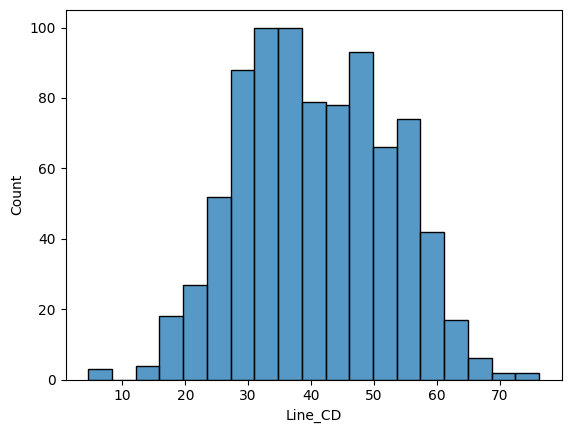

In [36]:
# 데이터의 분포를 확인하기 위해 히스토그램을 이용한다

sns.histplot(data=df1_photo, x='Line_CD')

<Axes: xlabel='Line_CD', ylabel='Count'>

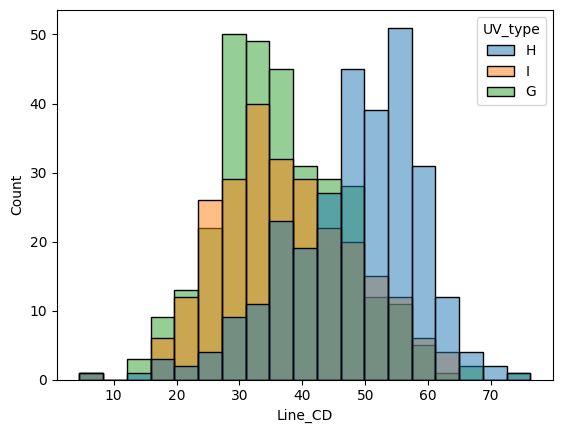

In [37]:
# UV 타입에선 타입 : G-line / H-line / I-line 총 3개의 라인이 있다는 것을 알고있다.

# 라인에 따른 데이터의 분포를 확인하기 위해 층별화를 그린다

sns.histplot(data=df1_photo, x='Line_CD', hue='UV_type')

### [해석]

### 우리는 라인의 적정 거리는 25 ~ 55nm으로 알고 있다.

### G라인과 I라인은 정규분포의 모습을 보이나 H라인의 경우에는 우측으로 치우친 모습을 띄고 있다.

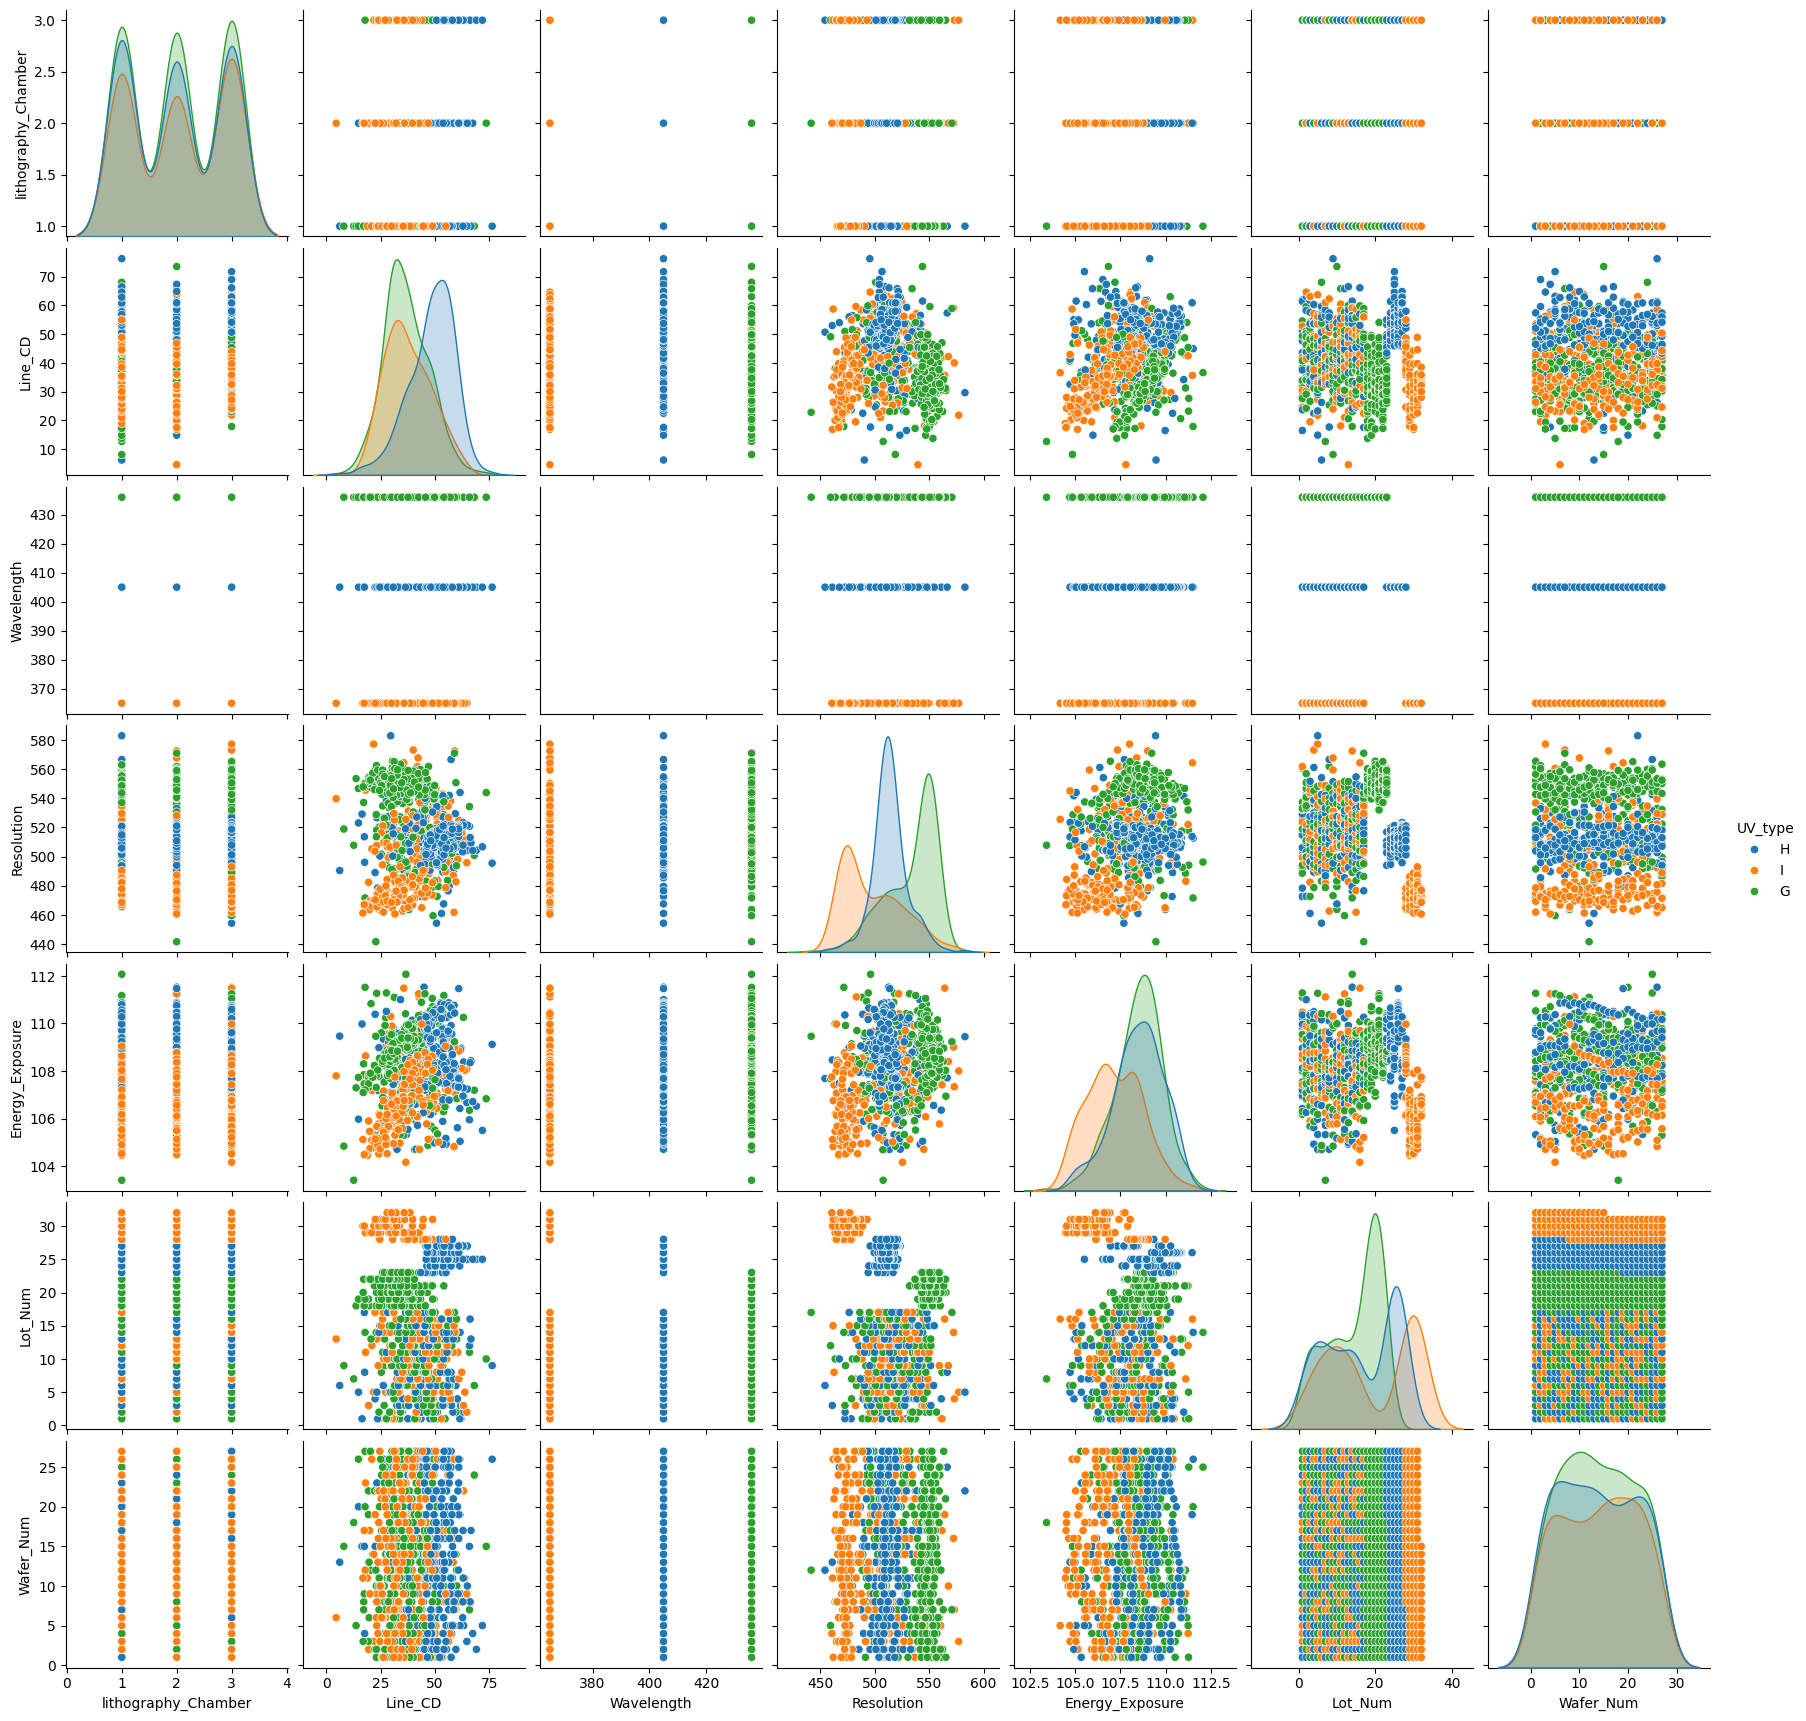

In [38]:
# 모든 숫자데이터의 층별화 / 히스토그램 / 산점도를 확인해보자

sns.pairplot(data=df1_photo, hue='UV_type')

<Axes: xlabel='Wavelength', ylabel='Count'>

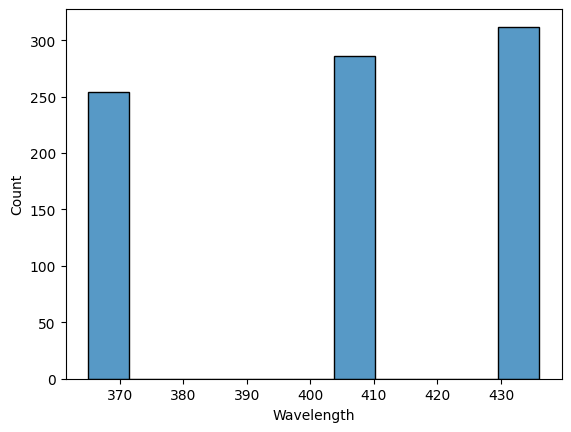

In [39]:
# 데이터의 분포를 확인하기 위해 히스토그램을 이용한다

sns.histplot(data=df1_photo, x='Wavelength')

In [40]:
# 빈도수를 확인해보자

df1_photo['Wavelength'].value_counts()

,count
Wavelength,
436,312
405,286
365,254


<Axes: xlabel='Wavelength', ylabel='Count'>

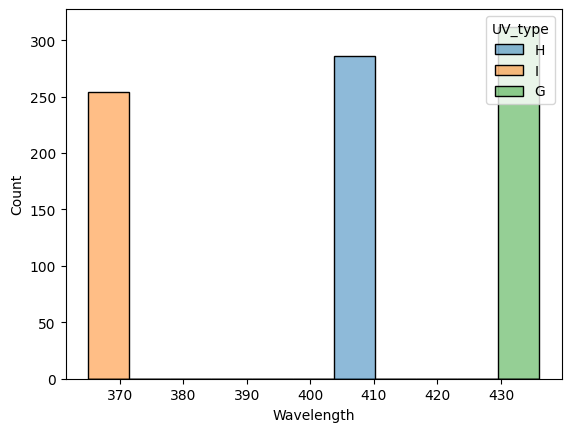

In [41]:
sns.histplot(data=df1_photo, x='Wavelength', hue='UV_type')

<Axes: xlabel='UV_type', ylabel='count'>

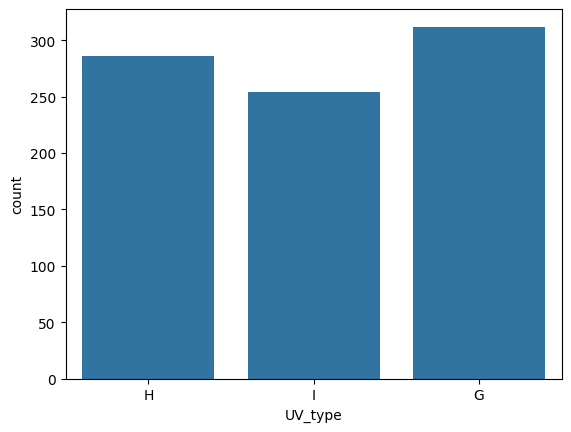

In [42]:
# 범주형 데이터 시각화를 진행해보자

sns.countplot(data=df1_photo, x='UV_type')

# 2. 잘못된 값들을 처리하자 ( 이상치 데이터 처리 )

## 2.1 Oxid.csv 데이터 이상치 처리

In [43]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

In [44]:
df1_oxid = pd.read_csv(github_csv_url + '/Oxid.csv')

df1_etch = pd.read_csv(github_csv_url + '/Etching.csv')

## 이상치(Outlier)를 판단하는 기준

### 1. IQR ( 사분범위 : Inter Qunatile Range )
###   :  데이터를 오름차순 또는 내림차순으로 정렬한 뒤,
###      1/4 씩 나누어, 전체 데이터의 50% 데이터가 몰려있는 구간을 선택하는 방식

### 2. 표준편차 6배 (ESD) : 평균으로부터 각각 표준편차가 3배이상 떨어진 구간

### 3. 비즈니스 상 이상치라고 판단되는 값들

In [45]:
df1_oxid.describe()

,Ox_Chamber,Temp_OXid,ppm,Pressure,Oxid_time,thickness,Lot_Num,Wafer_Num
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000
mean,2.00000,1064.415784,33.202242,0.211374,123.201878,710.926810,16.281690,13.894366
std,0.81265,149.550147,8.494070,0.009067,76.285130,8.082856,9.116841,7.785951
min,1.00000,862.011276,21.070000,0.180000,-6.000000,681.435000,1.000000,1.000000
25%,1.00000,874.756813,22.450000,0.205000,52.000000,706.313000,8.000000,7.000000
50%,2.00000,1069.240209,33.420000,0.213000,116.000000,711.590500,16.000000,14.000000
75%,3.00000,1189.172249,40.452500,0.217000,217.000000,715.595000,24.000000,21.000000
max,3.00000,1339.476675,49.910000,0.229000,291.000000,737.402000,32.000000,27.000000


##################################################
#  IQR : 사분범위
##################################################

# 1/4 : min ~ 25%
# 2/4 : 25 ~ 50%
# 3/4 : 50 ~ 75%
# 4/4 : 75 ~ max

<Axes: xlabel='Oxid_time'>

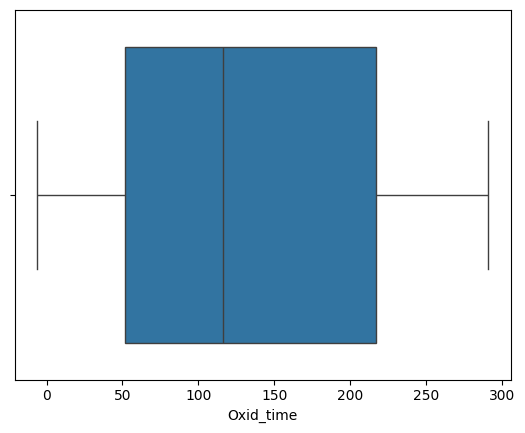

In [46]:
# 시각화를 진행해보자

sns.boxplot(data=df1_oxid, x='Oxid_time')

### [해석]

### 그려진 Box Plot을 보면 50 ~ 약220 정도에 박스가 그려진 것을 확인할 수 있다.
### 바로 이 구간을 IQR이라고 한다.

### 이때 이상치를 확인하는 공식은
### 25% 구간 (1사분위수) 또는 75% 구간 (3사분위수)에서 IQR * 1.5배 이상 떨어진 데이터를 이상치로 판단한다.
### 즉, 0과 약 280의 범위 밖에 존재하는 값을 이상치로 판단한다.

# 이상치 처리방식

# 1. 다른 값으로 대치하는 방식
# 2. 제거하는 방식

In [47]:
df1_oxid.describe()

,Ox_Chamber,Temp_OXid,ppm,Pressure,Oxid_time,thickness,Lot_Num,Wafer_Num
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000
mean,2.00000,1064.415784,33.202242,0.211374,123.201878,710.926810,16.281690,13.894366
std,0.81265,149.550147,8.494070,0.009067,76.285130,8.082856,9.116841,7.785951
min,1.00000,862.011276,21.070000,0.180000,-6.000000,681.435000,1.000000,1.000000
25%,1.00000,874.756813,22.450000,0.205000,52.000000,706.313000,8.000000,7.000000
50%,2.00000,1069.240209,33.420000,0.213000,116.000000,711.590500,16.000000,14.000000
75%,3.00000,1189.172249,40.452500,0.217000,217.000000,715.595000,24.000000,21.000000
max,3.00000,1339.476675,49.910000,0.229000,291.000000,737.402000,32.000000,27.000000


In [48]:
# Oxid_time의 음수값을 제거하여 이상치를 처리해보자

df1_oxid['Oxid_time']

,Oxid_time
0,62
1,137
2,128
3,90
4,98
...,...
847,21
848,22
849,21
850,20


In [49]:
# 음수값이 어디에 있는지 잘 보이지 않는다
# 조건값을 주어 음수값을 다시한번 확인해보자

cond1 = (df1_oxid['Oxid_time'] < 0)
df1_oxid.loc[cond1]

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime
220,3,Oxidation,dry,1190.831353,O2,35.47,0.207,-5,700.396,NOLSM22195,9,5,17-02-2019 PM 9:04:30
248,3,Oxidation,dry,1140.375541,O2,34.12,0.214,-5,721.300,NOLSM249106,10,6,17-02-2019 PM 9:04:30
333,1,Oxidation,dry,978.149281,O2,35.26,0.202,-2,687.497,NOLSM3341310,13,10,17-02-2019 PM 9:04:30
358,1,Oxidation,dry,1091.609203,O2,35.15,0.211,-6,703.879,NOLSM359148,14,8,17-02-2019 PM 9:04:30
761,2,Oxidation,wet,1268.333781,H2O,44.53,0.191,-2,686.530,NOLSM762296,29,6,17-02-2019 PM 9:04:30
762,2,Oxidation,wet,1274.752189,H2O,44.62,0.187,-6,691.168,NOLSM763297,29,7,17-02-2019 PM 9:04:30


In [50]:
# 데이터 수를 다시 확인해보기

df1_oxid.loc[cond1].count()

,0
Ox_Chamber,6
process,6
type,6
Temp_OXid,6
Vapor,6
ppm,6
Pressure,6
Oxid_time,6
thickness,6
No_Die,6


In [51]:
# 데이터를 삭제하기 전 원본 데이터를 유지시키기 위해 복제본을 활용한다.
# 지금은 이상치로 판단하지만 실제로는 이상치가 아닌 경우가 있다. 따라서 원본은 유지해야 한다.

df1_oxid['Oxid_time_Add'] = df1_oxid['Oxid_time']

df1_oxid

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime,Oxid_time_Add
0,1,Oxidation,dry,1138.979159,O2,32.80,0.200,62,699.443,NOLSM111,1,1,17-02-2019 PM 9:04:30,62
1,1,Oxidation,dry,1218.184551,O2,31.86,0.194,137,696.792,NOLSM212,1,2,17-02-2019 PM 9:04:30,137
2,1,Oxidation,dry,1062.467808,O2,39.51,0.217,128,705.471,NOLSM313,1,3,17-02-2019 PM 9:04:30,128
3,1,Oxidation,dry,1114.704773,O2,32.88,0.201,90,710.772,NOLSM414,1,4,17-02-2019 PM 9:04:30,90
4,1,Oxidation,dry,989.411946,O2,38.11,0.204,98,716.975,NOLSM515,1,5,17-02-2019 PM 9:04:30,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,3,Oxidation,wet,1275.182502,H2O,45.10,0.214,21,715.498,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,21
848,1,Oxidation,wet,1268.105427,H2O,45.07,0.215,22,707.179,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,22
849,1,Oxidation,wet,1279.160563,H2O,45.12,0.214,21,712.946,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,21
850,1,Oxidation,wet,1272.804948,H2O,45.34,0.213,20,711.987,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,20


In [52]:
cond1 = (df1_oxid['Oxid_time_Add'] < 0)
df1_oxid.loc[cond1]

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime,Oxid_time_Add
220,3,Oxidation,dry,1190.831353,O2,35.47,0.207,-5,700.396,NOLSM22195,9,5,17-02-2019 PM 9:04:30,-5
248,3,Oxidation,dry,1140.375541,O2,34.12,0.214,-5,721.300,NOLSM249106,10,6,17-02-2019 PM 9:04:30,-5
333,1,Oxidation,dry,978.149281,O2,35.26,0.202,-2,687.497,NOLSM3341310,13,10,17-02-2019 PM 9:04:30,-2
358,1,Oxidation,dry,1091.609203,O2,35.15,0.211,-6,703.879,NOLSM359148,14,8,17-02-2019 PM 9:04:30,-6
761,2,Oxidation,wet,1268.333781,H2O,44.53,0.191,-2,686.530,NOLSM762296,29,6,17-02-2019 PM 9:04:30,-2
762,2,Oxidation,wet,1274.752189,H2O,44.62,0.187,-6,691.168,NOLSM763297,29,7,17-02-2019 PM 9:04:30,-6


In [53]:
# 음수값의 컬럼을 NaN 값으로 대치하자

df1_oxid.loc[cond1,'Oxid_time_Add'] = np.nan

cond1 = (df1_oxid['Oxid_time'] < 0)
df1_oxid.loc[cond1]

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime,Oxid_time_Add
220,3,Oxidation,dry,1190.831353,O2,35.47,0.207,-5,700.396,NOLSM22195,9,5,17-02-2019 PM 9:04:30,NaN
248,3,Oxidation,dry,1140.375541,O2,34.12,0.214,-5,721.300,NOLSM249106,10,6,17-02-2019 PM 9:04:30,NaN
333,1,Oxidation,dry,978.149281,O2,35.26,0.202,-2,687.497,NOLSM3341310,13,10,17-02-2019 PM 9:04:30,NaN
358,1,Oxidation,dry,1091.609203,O2,35.15,0.211,-6,703.879,NOLSM359148,14,8,17-02-2019 PM 9:04:30,NaN
761,2,Oxidation,wet,1268.333781,H2O,44.53,0.191,-2,686.530,NOLSM762296,29,6,17-02-2019 PM 9:04:30,NaN
762,2,Oxidation,wet,1274.752189,H2O,44.62,0.187,-6,691.168,NOLSM763297,29,7,17-02-2019 PM 9:04:30,NaN


In [54]:
df1_oxid.describe()

,Ox_Chamber,Temp_OXid,ppm,Pressure,Oxid_time,thickness,Lot_Num,Wafer_Num,Oxid_time_Add
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,846.000000
mean,2.00000,1064.415784,33.202242,0.211374,123.201878,710.926810,16.281690,13.894366,124.106383
std,0.81265,149.550147,8.494070,0.009067,76.285130,8.082856,9.116841,7.785951,75.791886
min,1.00000,862.011276,21.070000,0.180000,-6.000000,681.435000,1.000000,1.000000,0.000000
25%,1.00000,874.756813,22.450000,0.205000,52.000000,706.313000,8.000000,7.000000,56.000000
50%,2.00000,1069.240209,33.420000,0.213000,116.000000,711.590500,16.000000,14.000000,116.500000
75%,3.00000,1189.172249,40.452500,0.217000,217.000000,715.595000,24.000000,21.000000,217.750000
max,3.00000,1339.476675,49.910000,0.229000,291.000000,737.402000,32.000000,27.000000,291.000000


In [55]:
# IQR을 이용해 이상치를 처리해보자

# 1/4 분위수를 확인

df1_oxid['Oxid_time_Add'].quantile(0.25)

np.float64(56.0)

In [56]:
# 3/4 분위수를 확인

df1_oxid['Oxid_time_Add'].quantile(0.75)

np.float64(217.75)

In [57]:
q3 = df1_oxid['Oxid_time_Add'].quantile(0.75)
q1 = df1_oxid['Oxid_time_Add'].quantile(0.25)

iqr = q3 - q1
iqr

np.float64(161.75)

In [58]:
# iqr의 범위는 IQR값에 1.5를 곱하면 된다.

iqr = (q3 - q1) * 1.5
iqr

np.float64(242.625)

In [59]:
# IQR을 벗어나는 범위를 계산해보자

# 3/4분위에서는 + 연산

iqr + q3

np.float64(460.375)

In [60]:
# 1/4분위에서는 - 연산

q1 - iqr

np.float64(-186.625)

<Axes: xlabel='Oxid_time_Add'>

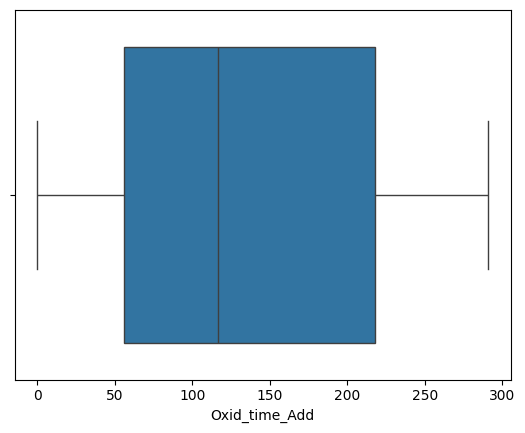

In [61]:
sns.boxplot(data=df1_oxid, x='Oxid_time_Add')

In [62]:
# IQR을 벗어나는 데이터를 찾아 NaN으로 대치

cond11 = df1_oxid[('Oxid_time_Add')] > (iqr + q3)
cond21 = df1_oxid[('Oxid_time_Add')] < (q1 - iqr)

df1_oxid.loc[cond11 | cond21 , 'Oxid_time_Add'] = np.nan

<Axes: xlabel='Oxid_time_Add'>

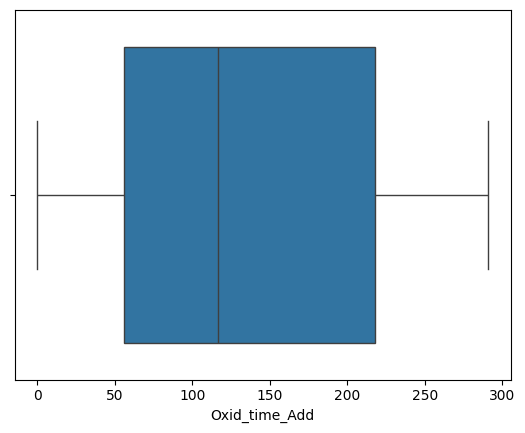

In [63]:
sns.boxplot(data=df1_oxid, x='Oxid_time_Add')

### [해석]

### 이상치가 처리된 데이터의 수가 6개 이므로 boxplot에서는 큰 차이가 없는듯 보인다.

## 2.2 Etching.csv 데이터 이상치 처리

In [64]:
df1_etch.describe()

,Unnamed: 0,Etching_Chamber,Temp_Etching,Source_Power,Selectivity,Lot_Num,Wafer_Num,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,851.000000,851.000000,851.000000,851.000000
mean,425.50000,1.967136,71.147822,51.227459,1.032140,16.281690,13.894366,296.633373,311.276439,347.799401,404.940012
std,246.09551,0.830584,0.824158,0.634215,0.016238,9.116841,7.785951,125.378446,125.714630,125.774630,125.790535
min,0.00000,1.000000,68.150000,49.342000,0.984000,1.000000,1.000000,-49.000000,-34.650000,2.000000,59.380000
25%,212.75000,1.000000,70.709750,50.794500,1.022000,8.000000,7.000000,202.000000,216.525000,252.880000,310.185000
50%,425.50000,2.000000,71.220500,51.247000,1.033500,16.000000,14.000000,281.000000,295.970000,332.480000,389.630000
75%,638.25000,3.000000,71.656500,51.698250,1.043000,24.000000,21.000000,372.000000,386.675000,423.050000,480.355000
max,851.00000,3.000000,73.081000,53.272000,1.076000,32.000000,27.000000,687.000000,700.240000,736.510000,793.500000


In [65]:
# 이상치 데이터 Nan 처리

df1_etch['Thin Film 4_Add'] = df1_etch['Thin Film 4']

cond1 = (df1_etch['Thin Film 4_Add'] < 0 )
df1_etch.loc[cond1, 'Thin Film 4_Add']= np.nan

In [66]:
df1_etch.describe()

,Unnamed: 0,Etching_Chamber,Temp_Etching,Source_Power,Selectivity,Lot_Num,Wafer_Num,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,851.000000,851.000000,851.000000,851.000000,848.000000
mean,425.50000,1.967136,71.147822,51.227459,1.032140,16.281690,13.894366,296.633373,311.276439,347.799401,404.940012,297.814858
std,246.09551,0.830584,0.824158,0.634215,0.016238,9.116841,7.785951,125.378446,125.714630,125.774630,125.790535,124.009359
min,0.00000,1.000000,68.150000,49.342000,0.984000,1.000000,1.000000,-49.000000,-34.650000,2.000000,59.380000,13.000000
25%,212.75000,1.000000,70.709750,50.794500,1.022000,8.000000,7.000000,202.000000,216.525000,252.880000,310.185000,203.000000
50%,425.50000,2.000000,71.220500,51.247000,1.033500,16.000000,14.000000,281.000000,295.970000,332.480000,389.630000,282.000000
75%,638.25000,3.000000,71.656500,51.698250,1.043000,24.000000,21.000000,372.000000,386.675000,423.050000,480.355000,372.250000
max,851.00000,3.000000,73.081000,53.272000,1.076000,32.000000,27.000000,687.000000,700.240000,736.510000,793.500000,687.000000


### [해석]

### Thin Film 4 항목에는 음수값이 조회되지만 Thin Film 4_Add에는 최소값이 13으로 나타났다.

In [67]:
# 이상치 데이터 Nan 처리

df1_etch['Thin Film 3_Add'] = df1_etch['Thin Film 3']

cond1 = (df1_etch['Thin Film 3_Add'] < 0 )
df1_etch.loc[cond1, 'Thin Film 3_Add']= np.nan

In [68]:
df1_etch.describe()

,Unnamed: 0,Etching_Chamber,Temp_Etching,Source_Power,Selectivity,Lot_Num,Wafer_Num,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,851.000000,851.000000,851.000000,851.000000,848.000000,848.000000
mean,425.50000,1.967136,71.147822,51.227459,1.032140,16.281690,13.894366,296.633373,311.276439,347.799401,404.940012,297.814858,312.458125
std,246.09551,0.830584,0.824158,0.634215,0.016238,9.116841,7.785951,125.378446,125.714630,125.774630,125.790535,124.009359,124.349720
min,0.00000,1.000000,68.150000,49.342000,0.984000,1.000000,1.000000,-49.000000,-34.650000,2.000000,59.380000,13.000000,27.170000
25%,212.75000,1.000000,70.709750,50.794500,1.022000,8.000000,7.000000,202.000000,216.525000,252.880000,310.185000,203.000000,217.532500
50%,425.50000,2.000000,71.220500,51.247000,1.033500,16.000000,14.000000,281.000000,295.970000,332.480000,389.630000,282.000000,296.695000
75%,638.25000,3.000000,71.656500,51.698250,1.043000,24.000000,21.000000,372.000000,386.675000,423.050000,480.355000,372.250000,387.002500
max,851.00000,3.000000,73.081000,53.272000,1.076000,32.000000,27.000000,687.000000,700.240000,736.510000,793.500000,687.000000,700.240000


### [해석]

### Thin Film 3 항목에는 음수값이 조회되지만 Thin Film 3_Add에는 최소값이 27로 나타났다.

In [69]:
# 표준편차를 이용해 이상치를 제거해보자

df1_etch['Thin Film 4_Add'].describe()

,Thin Film 4_Add
count,848.000000
mean,297.814858
std,124.009359
min,13.000000
25%,203.000000
50%,282.000000
75%,372.250000
max,687.000000


In [70]:
df1_etch['Thin Film 4_Add'].std()

124.00935873575492

In [71]:
# 평균으로 부터 3배 떨어진 값

esd = (df1_etch['Thin Film 4_Add'].std()) * 3

upper_esd = df1_etch['Thin Film 4_Add'].mean() + esd
lower_esd = df1_etch['Thin Film 4_Add'].mean() - esd

In [72]:
cond11 = (df1_etch['Thin Film 4_Add'] > upper_esd)

df1_etch.loc[cond11]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add
55,55,2,Etching,71.472,51.805,1.033,NOLSM5632,3,2,17-02-2019 PM 9:04:30,683.0,698.46,735.05,792.22,683.0,698.46
64,64,1,Etching,70.977,50.912,1.024,NOLSM65311,3,11,17-02-2019 PM 9:04:30,687.0,700.24,736.51,793.50,687.0,700.24
323,323,2,Etching,71.456,50.481,1.037,NOLSM3241227,12,27,17-02-2019 PM 9:04:30,670.0,685.38,721.95,779.04,670.0,685.38
356,356,3,Etching,71.161,52.149,1.045,NOLSM357146,14,6,17-02-2019 PM 9:04:30,680.0,695.17,731.80,788.91,680.0,695.17
654,654,2,Etching,72.319,51.308,1.033,NOLSM655257,25,7,17-02-2019 PM 9:04:30,674.0,690.43,727.34,784.36,674.0,690.43


In [73]:
cond21 = (df1_etch['Thin Film 4_Add'] < lower_esd)

df1_etch.loc[cond21]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add


In [74]:
cond11 = (df1_etch['Thin Film 4_Add'] > upper_esd)
cond21 = (df1_etch['Thin Film 4_Add'] < lower_esd)

df1_etch.loc[cond11 | cond21, 'Thin Film 4_Add'] = np.nan

In [75]:
df1_etch.describe()

,Unnamed: 0,Etching_Chamber,Temp_Etching,Source_Power,Selectivity,Lot_Num,Wafer_Num,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add
count,852.00000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,851.000000,851.000000,851.000000,851.000000,843.000000,848.000000
mean,425.50000,1.967136,71.147822,51.227459,1.032140,16.281690,13.894366,296.633373,311.276439,347.799401,404.940012,295.555160,312.458125
std,246.09551,0.830584,0.824158,0.634215,0.016238,9.116841,7.785951,125.378446,125.714630,125.774630,125.790535,120.840279,124.349720
min,0.00000,1.000000,68.150000,49.342000,0.984000,1.000000,1.000000,-49.000000,-34.650000,2.000000,59.380000,13.000000,27.170000
25%,212.75000,1.000000,70.709750,50.794500,1.022000,8.000000,7.000000,202.000000,216.525000,252.880000,310.185000,202.500000,217.532500
50%,425.50000,2.000000,71.220500,51.247000,1.033500,16.000000,14.000000,281.000000,295.970000,332.480000,389.630000,280.000000,296.695000
75%,638.25000,3.000000,71.656500,51.698250,1.043000,24.000000,21.000000,372.000000,386.675000,423.050000,480.355000,369.500000,387.002500
max,851.00000,3.000000,73.081000,53.272000,1.076000,32.000000,27.000000,687.000000,700.240000,736.510000,793.500000,669.000000,700.240000


### [해석]

### Thin Film 4의 최대값과 최소값이 변경된 걸 확인할 수 있다.

# 3. 분석을 다양하게 하기 위한 파생 변수 생성

In [76]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

In [77]:
df1_oxid = pd.read_csv(github_csv_url + '/Oxid.csv')

df1_oxid

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime
0,1,Oxidation,dry,1138.979159,O2,32.80,0.200,62,699.443,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,1,Oxidation,dry,1218.184551,O2,31.86,0.194,137,696.792,NOLSM212,1,2,17-02-2019 PM 9:04:30
2,1,Oxidation,dry,1062.467808,O2,39.51,0.217,128,705.471,NOLSM313,1,3,17-02-2019 PM 9:04:30
3,1,Oxidation,dry,1114.704773,O2,32.88,0.201,90,710.772,NOLSM414,1,4,17-02-2019 PM 9:04:30
4,1,Oxidation,dry,989.411946,O2,38.11,0.204,98,716.975,NOLSM515,1,5,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,3,Oxidation,wet,1275.182502,H2O,45.10,0.214,21,715.498,NOLSM8483211,32,11,17-02-2019 PM 9:04:30
848,1,Oxidation,wet,1268.105427,H2O,45.07,0.215,22,707.179,NOLSM8493212,32,12,17-02-2019 PM 9:04:30
849,1,Oxidation,wet,1279.160563,H2O,45.12,0.214,21,712.946,NOLSM8503213,32,13,17-02-2019 PM 9:04:30
850,1,Oxidation,wet,1272.804948,H2O,45.34,0.213,20,711.987,NOLSM8513214,32,14,17-02-2019 PM 9:04:30


# 파생변수 : 기존의 변수에 계산식을 넣거나, 특정 조건에 따라 새로 데이터를 분류해 새로운 항목으로 만든 값

In [78]:
df1_oxid['thickness'].describe()

,thickness
count,852.000000
mean,710.926810
std,8.082856
min,681.435000
25%,706.313000
50%,711.590500
75%,715.595000
max,737.402000


In [79]:
# thickness는 700나노미터 이상인 데이터만 다음 공정으로 넘어갈 수 있다.

# 700미만의 데이터는 보강작업이 필요하다.

cond1 = (df1_oxid['thickness'] < 700)

df1_oxid.loc[cond1]

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,Lot_Num,Wafer_Num,Datetime
0,1,Oxidation,dry,1138.979159,O2,32.80,0.200,62,699.443,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,1,Oxidation,dry,1218.184551,O2,31.86,0.194,137,696.792,NOLSM212,1,2,17-02-2019 PM 9:04:30
5,1,Oxidation,wet,979.109703,H2O,39.93,0.204,132,698.725,NOLSM616,1,6,17-02-2019 PM 9:04:30
7,1,Oxidation,dry,1096.241849,O2,28.60,0.199,291,696.438,NOLSM818,1,8,17-02-2019 PM 9:04:30
10,2,Oxidation,dry,1077.751749,O2,32.59,0.189,87,689.049,NOLSM11111,1,11,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,2,Oxidation,dry,870.794989,O2,22.18,0.192,199,690.969,NOLSM461182,18,2,17-02-2019 PM 9:04:30
761,2,Oxidation,wet,1268.333781,H2O,44.53,0.191,-2,686.530,NOLSM762296,29,6,17-02-2019 PM 9:04:30
762,2,Oxidation,wet,1274.752189,H2O,44.62,0.187,-6,691.168,NOLSM763297,29,7,17-02-2019 PM 9:04:30
814,2,Oxidation,wet,1268.359218,H2O,44.61,0.207,14,695.764,NOLSM815315,31,5,17-02-2019 PM 9:04:30


In [80]:
# cond1의 조건에 맞으면 'reinfor'
df1_oxid.loc[cond1, 'thickness_reinfor'] = 'reinfor'

# cond1의 조건에 맞지않으면 'normal'
df1_oxid.loc[~cond1, 'thickness_reinfor'] = 'normal'

In [81]:
# 새로 추가한 파생변수의 값이 어떻게 구성되어 있는지 확인하자
df1_oxid['thickness_reinfor'].value_counts()

,count
thickness_reinfor,
normal,770
reinfor,82


In [82]:
# 보강이 필요한 데이터와 보강이 필요없는 데이터의 공정 시간의 차이를 확인해보자
#
# 숫자형 데이터를 문자형 데이터로 변경하여 집단간 평균값 등을 분석하는 방법임

df1_oxid.pivot_table(index='thickness_reinfor', values='Oxid_time')

,Oxid_time
thickness_reinfor,
normal,125.045455
reinfor,105.890244


In [83]:
# 여러개의 컬럼을 지정하여 확인해보자

# 데이터 항목을 리스트 형식으로 선언해 사용한다.
df1_oxid.pivot_table(index='thickness_reinfor', values=['Oxid_time','ppm','Pressure','Temp_OXid'])

,Oxid_time,Pressure,Temp_OXid,ppm
thickness_reinfor,,,,
normal,125.045455,0.211891,1062.494658,33.107623
reinfor,105.890244,0.206524,1082.455629,34.090732


# 결과를 살펴보니 Oxid_time과 Temp_OXid의 차이가 존재하는 것으로 확인된다.

In [84]:
df1_litho = pd.read_csv(github_csv_url + '/Photo_lithography.csv')
df1_litho

,lithography_Chamber,Line_CD,Lamp,UV_type,Wavelength,Resolution,Energy_Exposure,No_Die,Lot_Num,Wafer_Num,Datetime
0,1,30.959,Hg-Arc,H,405,516.657,109.769,NOLSM111,1,1,17-02-2019 PM 9:04:30
1,2,29.653,Hg-Arc,H,405,501.894,107.102,NOLSM212,1,2,17-02-2019 PM 9:04:30
2,3,28.063,Hg-Arc,I,365,506.750,110.471,NOLSM313,1,3,17-02-2019 PM 9:04:30
3,1,31.556,Hg-Arc,I,365,537.603,107.072,NOLSM414,1,4,17-02-2019 PM 9:04:30
4,2,31.969,Hg-Arc,I,365,560.574,108.073,NOLSM515,1,5,17-02-2019 PM 9:04:30
...,...,...,...,...,...,...,...,...,...,...,...
847,3,32.525,Hg-Arc,I,365,468.930,106.744,NOLSM8483211,32,11,17-02-2019 PM 9:04:30
848,1,28.001,Hg-Arc,I,365,469.586,106.174,NOLSM8493212,32,12,17-02-2019 PM 9:04:30
849,2,32.110,Hg-Arc,I,365,476.399,106.108,NOLSM8503213,32,13,17-02-2019 PM 9:04:30
850,3,35.822,Hg-Arc,I,365,476.997,106.765,NOLSM8513214,32,14,17-02-2019 PM 9:04:30


In [85]:
# Line_CD 값이 25~55나노미터 사이가 적정값이다.

cond11 = df1_litho['Line_CD'] < 25
cond21 = df1_litho['Line_CD'] > 55

df1_litho.loc[(cond11 | cond21), 'Range_check'] = 'check'
df1_litho.loc[~(cond11 | cond21), 'Range_check'] = 'normal'

In [86]:
df1_litho['Range_check'].value_counts()

,count
Range_check,
normal,666
check,186


In [87]:
df1_ecth = pd.read_csv(github_csv_url + '/Etching.csv')

df1_ecth

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09


In [88]:
# 에칭작업을 통해 실제 깍인 두께를 계산해보면

df1_ecth['Thin Film 1'] - df1_ecth['Thin Film 4']

,0
0,110.38
1,109.11
2,106.80
3,109.93
4,109.85
...,...
847,108.91
848,107.66
849,108.21
850,107.09


In [89]:
# 40분 동안 깍인 두께를 기준으로 1분에 깍인 두께를 계산해보자

(df1_ecth['Thin Film 1'] - df1_ecth['Thin Film 4']) / 40

,0
0,2.75950
1,2.72775
2,2.67000
3,2.74825
4,2.74625
...,...
847,2.72275
848,2.69150
849,2.70525
850,2.67725


In [90]:
# 새로운 파생변수로 선언해 저장한다.

df1_ecth['etch_rate'] = (df1_ecth['Thin Film 1'] - df1_ecth['Thin Film 4']) / 40

df1_ecth['etch_rate']

,etch_rate
0,2.75950
1,2.72775
2,2.67000
3,2.74825
4,2.74625
...,...
847,2.72275
848,2.69150
849,2.70525
850,2.67725


# 분석계획서에 Etching Rate와 Target(실제 작업 수치)의 상관성을 확인하겠다고 미리 정의함

# 4. 비어 있는 데이터는 어떻게 처리해야 하는가? (결측 데이터)

In [91]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

In [92]:
df1_ecth = pd.read_csv(github_csv_url + '/Etching.csv')

In [93]:
# 결측치가 포함된 데이터를 삭제하는 경우에는 데이터Row가 모두 삭제되기 때문에 지향하지 않는다
cond1 = (df1_etch['Thin Film 3'] < 0)

df1_etch['Thin Film 3_Add'] = df1_etch['Thin Film 3']
df1_etch.loc[cond1, 'Thin Film 3_Add'] = np.nan

In [94]:
df1_etch.isnull().sum()

,0
Unnamed: 0,0
Etching_Chamber,0
Process 3,0
Temp_Etching,0
Source_Power,0
Selectivity,0
No_Die,0
Lot_Num,0
Wafer_Num,0
Datetime,0


In [95]:
cond1 = (df1_etch['Thin Film 4'] < 0)

df1_etch['Thin Film 4_Add'] = df1_etch['Thin Film 4']
df1_etch.loc[cond1, 'Thin Film 4_Add'] = np.nan

In [96]:
df1_etch.isnull().sum()

,0
Unnamed: 0,0
Etching_Chamber,0
Process 3,0
Temp_Etching,0
Source_Power,0
Selectivity,0
No_Die,0
Lot_Num,0
Wafer_Num,0
Datetime,0


In [97]:
cond1 = (df1_etch['Thin Film 4_Add'].isnull())
df1_etch.loc[cond1]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add
211,211,2,Etching,69.897,50.484,1.023,NOLSM212823,8,23,17-02-2019 PM 9:04:30,-49.0,-34.65,2.00,59.38,NaN,NaN
332,332,2,Etching,70.060,51.141,1.047,NOLSM333139,13,9,17-02-2019 PM 9:04:30,-45.0,-30.86,5.55,62.86,NaN,NaN
376,376,2,Etching,70.794,50.944,1.026,NOLSM3771426,14,26,17-02-2019 PM 9:04:30,-18.0,-2.73,34.28,91.30,NaN,NaN
702,702,2,Etching,72.289,51.790,1.045,NOLSM703271,27,1,17-02-2019 PM 9:04:30,NaN,NaN,NaN,NaN,NaN,NaN


# 결측치 처리 방법

# - 제거
# - 대치 : 평균값 또는 중앙값과 같은 대표값으로 대치 할 수 있다.
#        : 알고리즘을 이용해, 주변 row값을 참고하여 대치하는 방법도 있다.

In [98]:
# 제거 방법

# 결측치를 포함하고 있는 모든 Row를 삭제한다.
df1_etch.dropna()

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38,251.0,267.06
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11,317.0,332.74
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80,411.0,424.21
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93,256.0,272.28
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85,419.0,434.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91,177.0,192.10
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66,180.0,194.33
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21,142.0,156.72
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09,127.0,140.41


In [99]:
df1_etch2 = df1_etch.dropna()

In [100]:
# 결측치를 다시 확인해보자.

df1_etch2.isnull().sum()

,0
Unnamed: 0,0
Etching_Chamber,0
Process 3,0
Temp_Etching,0
Source_Power,0
Selectivity,0
No_Die,0
Lot_Num,0
Wafer_Num,0
Datetime,0


In [101]:
# 대표값을 이용해 결측치를 대치하는 방법

df1_etch['Thin Film 4_Add']

,Thin Film 4_Add
0,251.0
1,317.0
2,411.0
3,256.0
4,419.0
...,...
847,177.0
848,180.0
849,142.0
850,127.0


In [102]:
# 결측치를 특정값으로 대치해보자

df1_etch['Thin Film 4(missing)'] = df1_etch['Thin Film 4_Add'].fillna(0)

In [103]:
cond1 = (df1_etch['Thin Film 4_Add'].isnull())
df1_etch.loc[cond1]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing)
211,211,2,Etching,69.897,50.484,1.023,NOLSM212823,8,23,17-02-2019 PM 9:04:30,-49.0,-34.65,2.00,59.38,NaN,NaN,0.0
332,332,2,Etching,70.060,51.141,1.047,NOLSM333139,13,9,17-02-2019 PM 9:04:30,-45.0,-30.86,5.55,62.86,NaN,NaN,0.0
376,376,2,Etching,70.794,50.944,1.026,NOLSM3771426,14,26,17-02-2019 PM 9:04:30,-18.0,-2.73,34.28,91.30,NaN,NaN,0.0
702,702,2,Etching,72.289,51.790,1.045,NOLSM703271,27,1,17-02-2019 PM 9:04:30,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [104]:
# 평균값으로 대치

df1_etch['Thin Film 4(missing2)'] = df1_etch['Thin Film 4_Add'].fillna(df1_etch['Thin Film 4_Add'].mean())

In [105]:
cond1 = (df1_etch['Thin Film 4_Add'].isnull())
df1_etch.loc[cond1]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2)
211,211,2,Etching,69.897,50.484,1.023,NOLSM212823,8,23,17-02-2019 PM 9:04:30,-49.0,-34.65,2.00,59.38,NaN,NaN,0.0,297.814858
332,332,2,Etching,70.060,51.141,1.047,NOLSM333139,13,9,17-02-2019 PM 9:04:30,-45.0,-30.86,5.55,62.86,NaN,NaN,0.0,297.814858
376,376,2,Etching,70.794,50.944,1.026,NOLSM3771426,14,26,17-02-2019 PM 9:04:30,-18.0,-2.73,34.28,91.30,NaN,NaN,0.0,297.814858
702,702,2,Etching,72.289,51.790,1.045,NOLSM703271,27,1,17-02-2019 PM 9:04:30,NaN,NaN,NaN,NaN,NaN,NaN,0.0,297.814858


In [106]:
# 중간값으로 대치

df1_etch['Thin Film 4(missing3)'] = df1_etch['Thin Film 4_Add'].fillna(df1_etch['Thin Film 4_Add'].median())

In [107]:
cond1 = (df1_etch['Thin Film 4_Add'].isnull())
df1_etch.loc[cond1]

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2),Thin Film 4(missing3)
211,211,2,Etching,69.897,50.484,1.023,NOLSM212823,8,23,17-02-2019 PM 9:04:30,-49.0,-34.65,2.00,59.38,NaN,NaN,0.0,297.814858,282.0
332,332,2,Etching,70.060,51.141,1.047,NOLSM333139,13,9,17-02-2019 PM 9:04:30,-45.0,-30.86,5.55,62.86,NaN,NaN,0.0,297.814858,282.0
376,376,2,Etching,70.794,50.944,1.026,NOLSM3771426,14,26,17-02-2019 PM 9:04:30,-18.0,-2.73,34.28,91.30,NaN,NaN,0.0,297.814858,282.0
702,702,2,Etching,72.289,51.790,1.045,NOLSM703271,27,1,17-02-2019 PM 9:04:30,NaN,NaN,NaN,NaN,NaN,NaN,0.0,297.814858,282.0


<Axes: xlabel='Thin Film 4_Add', ylabel='Count'>

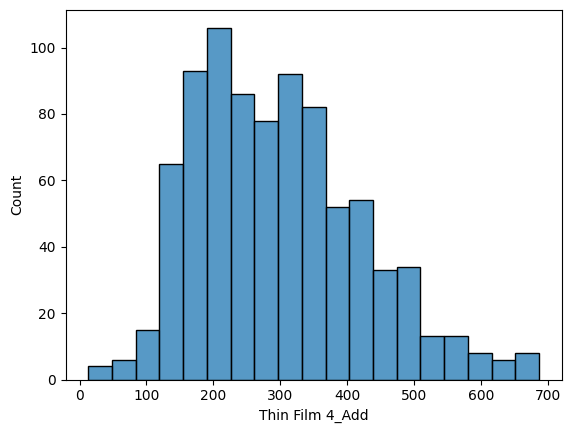

In [108]:
# 정규분포를 확인해보자

sns.histplot(data=df1_etch, x='Thin Film 4_Add')

### [해석]
### 정규분포의 모양이 중간값이나 평균값으로 대치를 해도 문제가 없어보이는 경우에 진행할 수 있으나
### 표준편차값도 크고 정규분포도 따르지 않는다면 지양한다.

In [109]:
df1_etch

,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2),Thin Film 4(missing3)
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38,251.0,267.06,251.0,251.0,251.0
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11,317.0,332.74,317.0,317.0,317.0
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80,411.0,424.21,411.0,411.0,411.0
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93,256.0,272.28,256.0,256.0,256.0
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85,419.0,434.98,419.0,419.0,419.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91,177.0,192.10,177.0,177.0,177.0
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66,180.0,194.33,180.0,180.0,180.0
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21,142.0,156.72,142.0,142.0,142.0
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09,127.0,140.41,127.0,127.0,127.0


### [해석]

### 위의 데이터와 같이 Datatime이 존재하는 경우에는 시간의 흐름에 따라 전,후 데이터가 유사하게 측정되는 경우가 있다.

### 이런경우에는 fillna함수를 이용해 앞,뒤의 값을 가지고와서 반영할 수 있다.
### 다만, 결측치가 많지만, 다른 컬럼을 활용해야 하는 경우에 주로 사용한다.

In [110]:
# 결측치 앞의 값으로 반영
df1_etch.fillna(method='ffill')

/tmp/ipykernel_2792/3814303878.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1_etch.fillna(method='ffill')


,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2),Thin Film 4(missing3)
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38,251.0,267.06,251.0,251.0,251.0
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11,317.0,332.74,317.0,317.0,317.0
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80,411.0,424.21,411.0,411.0,411.0
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93,256.0,272.28,256.0,256.0,256.0
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85,419.0,434.98,419.0,419.0,419.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91,177.0,192.10,177.0,177.0,177.0
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66,180.0,194.33,180.0,180.0,180.0
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21,142.0,156.72,142.0,142.0,142.0
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09,127.0,140.41,127.0,127.0,127.0


In [111]:
# 결측치 앞의 값으로 반영
df1_etch.fillna(method='ffill')

/tmp/ipykernel_2792/3814303878.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1_etch.fillna(method='ffill')


,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2),Thin Film 4(missing3)
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38,251.0,267.06,251.0,251.0,251.0
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11,317.0,332.74,317.0,317.0,317.0
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80,411.0,424.21,411.0,411.0,411.0
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93,256.0,272.28,256.0,256.0,256.0
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85,419.0,434.98,419.0,419.0,419.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91,177.0,192.10,177.0,177.0,177.0
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66,180.0,194.33,180.0,180.0,180.0
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21,142.0,156.72,142.0,142.0,142.0
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09,127.0,140.41,127.0,127.0,127.0


In [112]:
# 결측치 뒤의 값으로 반영
df1_etch.fillna(method='bfill')

/tmp/ipykernel_2792/3896547071.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1_etch.fillna(method='bfill')


,Unnamed: 0,Etching_Chamber,Process 3,Temp_Etching,Source_Power,Selectivity,No_Die,Lot_Num,Wafer_Num,Datetime,Thin Film 4,Thin Film 3,Thin Film 2,Thin Film 1,Thin Film 4_Add,Thin Film 3_Add,Thin Film 4(missing),Thin Film 4(missing2),Thin Film 4(missing3)
0,0,3,Etching,70.878,50.851,1.047,NOLSM111,1,1,17-02-2019 PM 9:04:30,251.0,267.06,303.82,361.38,251.0,267.06,251.0,251.0,251.0
1,1,2,Etching,69.561,52.283,1.051,NOLSM212,1,2,17-02-2019 PM 9:04:30,317.0,332.74,369.31,426.11,317.0,332.74,317.0,317.0,317.0
2,2,1,Etching,70.968,51.610,1.017,NOLSM313,1,3,17-02-2019 PM 9:04:30,411.0,424.21,460.65,517.80,411.0,424.21,411.0,411.0,411.0
3,3,1,Etching,70.146,51.286,1.027,NOLSM414,1,4,17-02-2019 PM 9:04:30,256.0,272.28,308.56,365.93,256.0,272.28,256.0,256.0,256.0
4,4,2,Etching,71.174,51.996,1.050,NOLSM515,1,5,17-02-2019 PM 9:04:30,419.0,434.98,471.65,528.85,419.0,434.98,419.0,419.0,419.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,847,3,Etching,71.550,50.601,1.015,NOLSM8483211,32,11,17-02-2019 PM 9:04:30,177.0,192.10,228.65,285.91,177.0,192.10,177.0,177.0,177.0
848,848,3,Etching,70.718,50.424,1.011,NOLSM8493212,32,12,17-02-2019 PM 9:04:30,180.0,194.33,230.76,287.66,180.0,194.33,180.0,180.0,180.0
849,849,2,Etching,71.295,50.602,1.015,NOLSM8503213,32,13,17-02-2019 PM 9:04:30,142.0,156.72,193.21,250.21,142.0,156.72,142.0,142.0,142.0
850,850,1,Etching,71.199,50.544,1.014,NOLSM8513214,32,14,17-02-2019 PM 9:04:30,127.0,140.41,176.87,234.09,127.0,140.41,127.0,127.0,127.0


# 5. 분석을 위한 전처리 마무리 ( 데이터 통합 )

In [113]:
import pandas as pd

In [114]:
df1_ecth = pd.read_csv(github_csv_url + '/Etching.csv')

df1_oxid = pd.read_csv(github_csv_url + '/Oxid.csv')
df1_soft = pd.read_csv(github_csv_url + '/Photo_Softbake.csv')
df1_litho = pd.read_csv(github_csv_url + '/Photo_lithography.csv')
df1_etch = pd.read_csv(github_csv_url + '/Etching.csv')
df1_ion = pd.read_csv(github_csv_url + '/Implant.csv')
df1_target = pd.read_csv(github_csv_url + '/Inspect.csv')

In [115]:
# 주요 인자들간의 관계를 파악해야 한다.
# => 병합해야 할 기준값을 찾아보자

df1_oxid.columns

Index(['Ox_Chamber', 'process', 'type', 'Temp_OXid', 'Vapor', 'ppm',
       'Pressure', 'Oxid_time', 'thickness', 'No_Die', 'Lot_Num', 'Wafer_Num',
       'Datetime'],
      dtype='object')

In [116]:
df1_soft.columns

Index(['Unnamed: 0', 'photo_soft_Chamber', 'process 2', 'resist_target',
       'N2_HMDS', 'pressure_HMDS', 'temp_HMDS', 'temp_HMDS_bake',
       'time_HMDS_bake', 'spin1', 'spin2', 'spin3', 'photoresist_bake',
       'temp_softbake', 'time_softbake', 'No_Die', 'Lot_Num', 'Wafer_Num',
       'Datetime'],
      dtype='object')

In [117]:
df1_litho.columns

Index(['lithography_Chamber', 'Line_CD', 'Lamp', 'UV_type', 'Wavelength',
       'Resolution', 'Energy_Exposure', 'No_Die', 'Lot_Num', 'Wafer_Num',
       'Datetime'],
      dtype='object')

In [118]:
df1_etch.columns

Index(['Unnamed: 0', 'Etching_Chamber', 'Process 3', 'Temp_Etching',
       'Source_Power', 'Selectivity', 'No_Die', 'Lot_Num', 'Wafer_Num',
       'Datetime', 'Thin Film 4', 'Thin Film 3', 'Thin Film 2', 'Thin Film 1'],
      dtype='object')

In [119]:
df1_ion.columns

Index(['Chamber_Num', 'process4', 'Flux60s', 'Flux90s', 'Flux160s', 'Flux480s',
       'Flux840s', 'input_Energy', 'Current', 'Temp_implantation',
       'Furance_Temp', 'RTA_Temp', 'No_Die', 'Lot_Num', 'Wafer_Num',
       'Datetime'],
      dtype='object')

In [120]:
df1_target.columns

Index(['Target', 'No_Die', 'Lot_Num', 'Wafer_Num', 'Datetime', 'Error_message',
       'Wafer_map'],
      dtype='object')

### [해석]

### 공통으로 들어가는 컬럼 중 'No_Die', 'Lot_Num', 'Wafer_Num', 'Datetime'이 있는것으로 확인됨
### 이 중 'No_Die'이 병합할 때 사용될 기준값이다.

### 또한, 'Ox_Chamber', 'photo_soft_Chamber', 'lithography_Chamber', 'Etching_Chamber', 'Chamber_Num'
### 등을 통해 챔버 가공 경로를 확인할 수 있다.

# - 데이터 병합 : 공통된 항목을 기준으로 병합을 실시 ( Key Column -> No_Die )
#     - Inner Join : Key Column에서 공통된 값들만 가져와서 병합
#     - Outer Join : Key Column에서 모든 값들을 가져와서 병합
#     - Left Join : 왼쪽 테이블을 기준으로 병합
#     - Right Join : 오른쪽 테이블을 기준으로 병합

In [121]:
d1 = pd.DataFrame([['홍길동',20, '남성'],['성춘향',40,'여성'],['이몽룔',50,'남성']],\
            columns=['이름','나이','성별'])

d2 = pd.DataFrame(data=[['홍길동','경기'],['성춘향','전북'],['허준','제주'],['홍길순','서울']],\
                 columns=['이름','주소'])

In [122]:
d1

,이름,나이,성별
0,홍길동,20,남성
1,성춘향,40,여성
2,이몽룔,50,남성


In [123]:
d2

,이름,주소
0,홍길동,경기
1,성춘향,전북
2,허준,제주
3,홍길순,서울


In [124]:
d1.loc[:,['이름','나이','성별']]

,이름,나이,성별
0,홍길동,20,남성
1,성춘향,40,여성
2,이몽룔,50,남성


In [125]:
d2[['이름','주소']]

,이름,주소
0,홍길동,경기
1,성춘향,전북
2,허준,제주
3,홍길순,서울


In [126]:
# Inner Join : Key Column에서 공통된 값들만 가져와서 병합

pd.merge(d1, d2, on='이름', how='inner')

,이름,나이,성별,주소
0,홍길동,20,남성,경기
1,성춘향,40,여성,전북


In [127]:
# Outer Join : Key Column에서 모든 값들을 가져와서 병합

pd.merge(d1, d2, on='이름', how='outer')

,이름,나이,성별,주소
0,성춘향,40.0,여성,전북
1,이몽룔,50.0,남성,NaN
2,허준,NaN,NaN,제주
3,홍길동,20.0,남성,경기
4,홍길순,NaN,NaN,서울


In [128]:
# Left Join : 왼쪽 테이블을 기준으로 병합

pd.merge(d1, d2, on='이름', how='left')

,이름,나이,성별,주소
0,홍길동,20,남성,경기
1,성춘향,40,여성,전북
2,이몽룔,50,남성,NaN


In [129]:
# Right Join : 오른쪽 테이블을 기준으로 병합

pd.merge(d1, d2, on='이름', how='right')

,이름,나이,성별,주소
0,홍길동,20.0,남성,경기
1,성춘향,40.0,여성,전북
2,허준,NaN,NaN,제주
3,홍길순,NaN,NaN,서울


In [130]:
# 실습용 데이터는 Key값이 모두 동일하게 존재하기 때문에 Inner Join을 실시한다.

m1 = pd.merge(df1_oxid, df1_soft, on='No_Die', how='inner', suffixes=('_oxid', '_soft'))
m2 = pd.merge(m1, df1_litho, on='No_Die', how='inner', suffixes=('', '_litho'))
m3 = pd.merge(m2, df1_ecth, on='No_Die', how='inner', suffixes=('', '_ecth'))
m4 = pd.merge(m3, df1_ion, on='No_Die', how='inner', suffixes=('', '_ion'))
m5 = pd.merge(m4, df1_target, on='No_Die', how='inner', suffixes=('', '_target'))

In [131]:
import pandas as pd

# 이전 병합으로 인해 데이터프레임이 변경될 수 있으므로, 초기 상태를 보장하기 위해 다시 로드합니다.
df1_oxid = pd.read_csv(github_csv_url + '/Oxid.csv')
df1_soft = pd.read_csv(github_csv_url + '/Photo_Softbake.csv')
df1_litho = pd.read_csv(github_csv_url + '/Photo_lithography.csv')
df1_etch = pd.read_csv(github_csv_url + '/Etching.csv')
df1_ion = pd.read_csv(github_csv_url + '/Implant.csv')
df1_target = pd.read_csv(github_csv_url + '/Inspect.csv')

# 병합 시 충돌을 일으키는 공통 식별자 컬럼들
common_identifier_cols = ['Lot_Num', 'Wafer_Num', 'Datetime']

# 각 데이터프레임에서 'No_Die'를 제외한 공통 컬럼에 고유한 접미사를 붙이는 함수
def rename_common_cols(df, suffix, common_cols, merge_key):
    df_copy = df.copy()
    for col in common_cols:
        if col != merge_key and col in df_copy.columns:
            df_copy.rename(columns={col: f'{col}{suffix}'}, inplace=True)
    return df_copy

# 열이 존재하는 경우 안전하게 'Unnamed: 0' 컬럼을 제거하는 함수입니다.
def drop_unnamed_col_if_exist(df):
    return df.drop(columns=['Unnamed: 0'], errors='ignore')

# df1_oxid를 기본 데이터프레임으로 시작합니다. 여기서 접미사 '_oxid'를 붙입니다.
merged_df = rename_common_cols(df1_oxid.copy(), '_oxid', common_identifier_cols, 'No_Die')

# df1_soft를 병합하고 접미사 '_soft'를 붙입니다. 'Unnamed: 0'도 제거합니다.
m1 = pd.merge(merged_df,
              rename_common_cols(drop_unnamed_col_if_exist(df1_soft), '_soft', common_identifier_cols, 'No_Die'),
              on='No_Die', how='inner')

# df1_litho를 병합하고 접미사 '_litho'를 붙입니다.
m2 = pd.merge(m1,
              rename_common_cols(df1_litho, '_litho', common_identifier_cols, 'No_Die'),
              on='No_Die', how='inner')

# df1_etch를 병합하고 접미사 '_etch'를 붙입니다. 'Unnamed: 0'도 제거합니다.
m3 = pd.merge(m2,
              rename_common_cols(drop_unnamed_col_if_exist(df1_etch), '_etch', common_identifier_cols, 'No_Die'),
              on='No_Die', how='inner')

# df1_ion을 계속해서 병합하고 접미사 '_ion'을 붙입니다.
m4 = pd.merge(m3,
              rename_common_cols(df1_ion, '_ion', common_identifier_cols, 'No_Die'),
              on='No_Die', how='inner')

# 마지막으로 df1_target을 병합하고 접미사 '_target'을 붙입니다.
m5 = pd.merge(m4,
              rename_common_cols(df1_target, '_target', common_identifier_cols, 'No_Die'),
              on='No_Die', how='inner')

# 최종 병합된 데이터프레임은 m5입니다.
print(m5.head())

   Ox_Chamber    process type    Temp_OXid Vapor    ppm  Pressure  Oxid_time  \
0           1  Oxidation  dry  1138.979159    O2  32.80     0.200         62   
1           1  Oxidation  dry  1218.184551    O2  31.86     0.194        137   
2           1  Oxidation  dry  1062.467808    O2  39.51     0.217        128   
3           1  Oxidation  dry  1114.704773    O2  32.88     0.201         90   
4           1  Oxidation  dry   989.411946    O2  38.11     0.204         98   

   thickness    No_Die  ...  RTA_Temp  Lot_Num_ion Wafer_Num_ion  \
0    699.443  NOLSM111  ...       154            1             1   
1    696.792  NOLSM212  ...       154            1             2   
2    705.471  NOLSM313  ...       155            1             3   
3    710.772  NOLSM414  ...       156            1             4   
4    716.975  NOLSM515  ...       155            1             5   

            Datetime_ion Target  Lot_Num_target  Wafer_Num_target  \
0  17-02-2019 ?? 9:04:30     96          

In [132]:
m5

,Ox_Chamber,process,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,No_Die,...,RTA_Temp,Lot_Num_ion,Wafer_Num_ion,Datetime_ion,Target,Lot_Num_target,Wafer_Num_target,Datetime_target,Error_message,Wafer_map
0,1,Oxidation,dry,1138.979159,O2,32.80,0.200,62,699.443,NOLSM111,...,154,1,1,17-02-2019 ?? 9:04:30,96,1,1,02-18-2018,none,[[0 0 0 ... 0 0 0]\n [0 0 0 ... 0 0 0]\n [0 0 ...
1,1,Oxidation,dry,1218.184551,O2,31.86,0.194,137,696.792,NOLSM212,...,154,1,2,17-02-2019 ?? 9:04:30,102,1,2,02-18-2018,none,[[0 0 0 ... 0 0 0]\n [0 0 0 ... 0 0 0]\n [0 0 ...
2,1,Oxidation,dry,1062.467808,O2,39.51,0.217,128,705.471,NOLSM313,...,155,1,3,17-02-2019 ?? 9:04:30,95,1,3,02-18-2018,none,[[0 0 0 ... 0 0 0]\n [0 0 0 ... 0 0 0]\n [0 0 ...
3,1,Oxidation,dry,1114.704773,O2,32.88,0.201,90,710.772,NOLSM414,...,156,1,4,17-02-2019 ?? 9:04:30,117,1,4,02-18-2018,none,[[0 0 0 ... 0 0 0]\n [0 0 0 ... 0 0 0]\n [0 0 ...
4,1,Oxidation,dry,989.411946,O2,38.11,0.204,98,716.975,NOLSM515,...,155,1,5,17-02-2019 ?? 9:04:30,143,1,5,02-18-2018,none,[[0 0 0 ... 0 0 0]\n [0 0 0 ... 0 0 0]\n [0 0 ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,3,Oxidation,wet,1275.182502,H2O,45.10,0.214,21,715.498,NOLSM8483211,...,152,32,11,28-02-2019 ?? 9:04:30,78,32,11,03-01-2018,none,[[0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 0 0 0 0 0 0 ...
848,1,Oxidation,wet,1268.105427,H2O,45.07,0.215,22,707.179,NOLSM8493212,...,152,32,12,28-02-2019 ?? 9:04:30,42,32,12,03-01-2018,none,[[0 0 0 0 0 0 0 0 0 0 2 2 2 2 1 1 0 0 0 0 0 0 ...
849,1,Oxidation,wet,1279.160563,H2O,45.12,0.214,21,712.946,NOLSM8503213,...,152,32,13,28-02-2019 ?? 9:04:30,42,32,13,03-01-2018,none,[[0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 1 0 0 0 0 0 0 ...
850,1,Oxidation,wet,1272.804948,H2O,45.34,0.213,20,711.987,NOLSM8513214,...,152,32,14,28-02-2019 ?? 9:04:30,24,32,14,03-01-2018,none,[[0 0 0 0 0 0 0 0 0 0 2 1 2 2 2 1 0 0 0 0 0 0 ...


In [133]:
# 불필요한 컬럼, 즉 중복된 컬럼이 무엇인지 확인한다.
# Key 컬럼을 제외한 컬럼에서 동일한 이름이 존재하는 경우 접미사 _x, _y를 자동으로 붙인다.

m5.columns

Index(['Ox_Chamber', 'process', 'type', 'Temp_OXid', 'Vapor', 'ppm',
       'Pressure', 'Oxid_time', 'thickness', 'No_Die', 'Lot_Num_oxid',
       'Wafer_Num_oxid', 'Datetime_oxid', 'photo_soft_Chamber', 'process 2',
       'resist_target', 'N2_HMDS', 'pressure_HMDS', 'temp_HMDS',
       'temp_HMDS_bake', 'time_HMDS_bake', 'spin1', 'spin2', 'spin3',
       'photoresist_bake', 'temp_softbake', 'time_softbake', 'Lot_Num_soft',
       'Wafer_Num_soft', 'Datetime_soft', 'lithography_Chamber', 'Line_CD',
       'Lamp', 'UV_type', 'Wavelength', 'Resolution', 'Energy_Exposure',
       'Lot_Num_litho', 'Wafer_Num_litho', 'Datetime_litho', 'Etching_Chamber',
       'Process 3', 'Temp_Etching', 'Source_Power', 'Selectivity',
       'Lot_Num_etch', 'Wafer_Num_etch', 'Datetime_etch', 'Thin Film 4',
       'Thin Film 3', 'Thin Film 2', 'Thin Film 1', 'Chamber_Num', 'process4',
       'Flux60s', 'Flux90s', 'Flux160s', 'Flux480s', 'Flux840s',
       'input_Energy', 'Current', 'Temp_implantation', 'Fu

In [134]:
df1 = m5
# 챔버의 경로를 만들어 보자

df1['Ox_Chamber'] + df1['photo_soft_Chamber']

,0
0,2
1,2
2,2
3,3
4,3
...,...
847,6
848,2
849,2
850,2


[해석]
데이터의 형식이 숫자형이므로 덧셈 연산이 되었다.

In [135]:
# 데이터 타입을 문자형으로 변환해 다시 작업하자.

df1['Ox_Chamber'].astype(str) + \
df1['photo_soft_Chamber'].astype(str) + \
df1['lithography_Chamber'].astype(str) + \
df1['Etching_Chamber'].astype(str) + \
df1['Chamber_Num'].astype(str)

,0
0,11133
1,11222
2,11311
3,12111
4,12222
...,...
847,33333
848,11133
849,11222
850,11311


In [136]:
# 데이터가 숫자로 구성되어 있다보니 숫자형으로 오해할 수 있다.
# 이를 방지하기 위해 아예 문자값을 추가하자.

df1['Chamber_route'] = 'route' + df1['Ox_Chamber'].astype(str) + \
                        df1['photo_soft_Chamber'].astype(str) + \
                        df1['lithography_Chamber'].astype(str) + \
                        df1['Etching_Chamber'].astype(str) + \
                        df1['Chamber_Num'].astype(str)

In [137]:
df1['Chamber_route']

,Chamber_route
0,route11133
1,route11222
2,route11311
3,route12111
4,route12222
...,...
847,route33333
848,route11133
849,route11222
850,route11311


In [138]:
# 경로별 웨이퍼 작업 수를 확인해 보자

df1['Chamber_route'].value_counts()

,count
Chamber_route,
route22222,34
route32222,34
route23222,34
route13222,31
route21222,30
route11222,29
route31222,26
route33222,25
route12222,21


### [해석]

### 챔버 경로별로 편차가 심하다.
### 실제 경로별 부하값에 따라 품질에 영향을 끼칠까?

In [139]:
df1.isnull().sum()

,0
Ox_Chamber,0
process,0
type,0
Temp_OXid,0
Vapor,0
...,...
Wafer_Num_target,0
Datetime_target,0
Error_message,0
Wafer_map,0


In [140]:
missing_values = df1.isnull().sum()
columns_with_missing_values = missing_values[missing_values > 0]

print("결측치가 존재하는 컬럼:")
print(columns_with_missing_values)

결측치가 존재하는 컬럼:
Line_CD            1
Resolution         1
Energy_Exposure    1
Thin Film 4        1
Thin Film 3        1
Thin Film 2        1
Thin Film 1        1
Flux60s            1
Flux90s            1
Flux160s           1
Furance_Temp       1
dtype: int64


### [해석]
### 결측치가 보이는 경우에는 이를 처리한 후 진행한다.